# Phase 1 Legal LM + Phase 2 L-NER — improved BIO character-boundary notebook

Run cells in order. The Phase 2 section uses the same custom Phase 1 model, audits label and character-offset integrity, trains token BIO tags alongside an exact character-level BIO boundary head, uses class-balanced losses for rarer labels, synchronizes the AMP scheduler with successful optimizer steps, and early-stops on strict validation macro-F1.


In [1]:
import os
import random
import json
import time
import zipfile
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.amp import autocast, GradScaler
from tqdm import tqdm
from huggingface_hub import login, hf_hub_download
from kaggle_secrets import UserSecretsClient
from tokenizers import Tokenizer
from tokenizers.models import BPE
from tokenizers.trainers import BpeTrainer
from tokenizers.pre_tokenizers import Whitespace

# ==========================================
# 1. Setup, Configuration & Authentication
# ==========================================
user_secrets = UserSecretsClient()
HF_TOKEN = user_secrets.get_secret("HF")
os.environ["HF_TOKEN"] = HF_TOKEN
login(token=HF_TOKEN)

print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())

HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"
# TRAIN_FILE = "Phase_1_Pretraining/Train/train_supreme_court.json"
TEST_FILE = "Phase_1_Pretraining/Test/test.json"

PROPORTIONS = {
    "train_supreme_court.json": 0.40,
    "train_high_courts.json": 0.25,
    "train_acts.json": 0.20,
    "train_tribunals.json": 0.15
}

# Hyperparameters
TRAIN_TOKENS = 150_000_000  # Adjust based on your time constraints
VAL_TOKENS = 4_000_000
TRAIN_BLOCK_SIZE = 2048
EPOCHS = 1
SEED = 42
random.seed(SEED)

# Custom Model Dimensions (~50M params)
MODEL_CONTEXT_LENGTH = 2048
N_EMBD = 512
N_LAYER = 15
N_HEAD = 8
N_KV_HEAD = 4 
VOCAB_SIZE = 32000

# Training Optimizations (2x T4 specific)
BATCH_SIZE = 2       # Scaled up for dual GPUs
ACCUMULATION_STEPS = 16 # Effective batch size = 32

# Generation Config
TARGET_GENERATION_WORDS = 128
MAX_GENERATION_TOKENS = 384
TEMPERATURE = 0.7
TOP_P = 0.9

# Paths
OUTPUT_DIR = "/kaggle/working/cs781_phase1"
MODEL_OUTPUT_DIR = os.path.join(OUTPUT_DIR, "legal-custom-final")
CHECKPOINT_PATH = os.path.join(OUTPUT_DIR, "latest_checkpoint.pt")
PREDICTION_PATH = os.path.join(OUTPUT_DIR, "prediction.json")
SUBMISSION_ZIP = os.path.join(OUTPUT_DIR, "submission.zip")
os.makedirs(OUTPUT_DIR, exist_ok=True)

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


CUDA available: True
GPU count: 2


In [2]:
# Phase 1 artifact resolution: choose the model AND tokenizer from the same Kaggle Dataset.
from pathlib import Path
import shutil

INPUT_ROOT = Path("/kaggle/input")
WORK_ROOT = Path("/kaggle/working/cs781_phase1")
WORK_ROOT.mkdir(parents=True, exist_ok=True)
(WORK_ROOT / "legal-custom-final").mkdir(parents=True, exist_ok=True)

# If more than one attached Kaggle Dataset contains both assets, set this to its folder name
# under /kaggle/input (the dataset slug). Example: PHASE1_ASSET_DATASET_SLUG = "my-phase1-model".
PHASE1_ASSET_DATASET_SLUG = None


def _input_dataset_slug(path):
    try:
        relative = path.relative_to(INPUT_ROOT)
        return relative.parts[0] if relative.parts else None
    except ValueError:
        return None


tokenizer_candidates = sorted(p for p in INPUT_ROOT.rglob("custom_bpe_scratch.json") if p.is_file())
model_candidates = sorted(p for p in INPUT_ROOT.rglob("pytorch_model.bin") if p.is_file())

if not tokenizer_candidates:
    raise FileNotFoundError("custom_bpe_scratch.json was not found under /kaggle/input. Attach your Phase 1 model Dataset.")
if not model_candidates:
    raise FileNotFoundError("pytorch_model.bin was not found under /kaggle/input. Attach your Phase 1 model Dataset.")

# Only dataset roots containing both filenames are candidates.
tokenizer_slugs = {_input_dataset_slug(p) for p in tokenizer_candidates}
model_slugs = {_input_dataset_slug(p) for p in model_candidates}
common_slugs = sorted(s for s in tokenizer_slugs.intersection(model_slugs) if s is not None)
if PHASE1_ASSET_DATASET_SLUG is not None:
    common_slugs = [s for s in common_slugs if s == PHASE1_ASSET_DATASET_SLUG]

if len(common_slugs) != 1:
    print("Tokenizer candidates:")
    for p in tokenizer_candidates:
        print(" ", p)
    print("Model candidates:")
    for p in model_candidates:
        print(" ", p)
    raise RuntimeError(
        "Cannot uniquely identify a Phase 1 Dataset containing both the tokenizer and model. "
        "Set PHASE1_ASSET_DATASET_SLUG above to the correct folder name under /kaggle/input."
    )

selected_slug = common_slugs[0]
selected_tokenizers = [p for p in tokenizer_candidates if _input_dataset_slug(p) == selected_slug]
selected_models = [p for p in model_candidates if _input_dataset_slug(p) == selected_slug]
if len(selected_tokenizers) != 1 or len(selected_models) != 1:
    print(f"Multiple asset files exist in Dataset {selected_slug!r}.")
    print("Tokenizers:", *selected_tokenizers, sep="\n  ")
    print("Models:", *selected_models, sep="\n  ")
    raise RuntimeError(
        "There must be exactly one tokenizer and one model checkpoint in the selected dataset root. "
        "Remove duplicates or edit the candidate-selection logic to choose the matching pair explicitly."
    )

tokenizer_src = selected_tokenizers[0]
model_src = selected_models[0]
TOKENIZER_PATH = WORK_ROOT / "custom_bpe_scratch.json"
MODEL_PATH = WORK_ROOT / "legal-custom-final" / "pytorch_model.bin"
shutil.copy2(tokenizer_src, TOKENIZER_PATH)
shutil.copy2(model_src, MODEL_PATH)
print("Selected Phase 1 Dataset:", selected_slug)
print("Tokenizer source:", tokenizer_src)
print("Model source:    ", model_src)
print("Tokenizer copied to:", TOKENIZER_PATH, f"({TOKENIZER_PATH.stat().st_size / 1e6:.2f} MB)")
print("Model copied to:    ", MODEL_PATH, f"({MODEL_PATH.stat().st_size / 1e6:.2f} MB)")


Selected Phase 1 Dataset: datasets
Tokenizer source: /kaggle/input/datasets/baihuwang07/phase1/custom_bpe_scratch.json
Model source:     /kaggle/input/datasets/baihuwang07/phase1/pytorch_model.bin
Tokenizer copied to: /kaggle/working/cs781_phase1/custom_bpe_scratch.json (1.87 MB)
Model copied to:     /kaggle/working/cs781_phase1/legal-custom-final/pytorch_model.bin (239.24 MB)


In [ ]:
data_files = {}
for filename in PROPORTIONS.keys():
    print(f"Downloading {filename}...")
    # The training files are located in the Phase_1_Pretraining/Train/ directory
    file_path = hf_hub_download(
        repo_id=HF_DATASET_REPO,
        filename=f"Phase_1_Pretraining/Train/{filename}",
        repo_type="dataset",
        token=HF_TOKEN
    )
    data_files[filename] = file_path

In [ ]:
# import json
# import os
# import random
# from collections import Counter, defaultdict

# class CustomScratchBPE:
#     def __init__(self, vocab_size, special_tokens=None):
#         self.vocab_size = vocab_size
#         self.special_tokens = special_tokens or ["[UNK]", "[PAD]", "[BOS]", "[EOS]"]
#         self.vocab = {}       
#         self.inv_vocab = {}   
#         self.merges = {}      
        
#     def train(self, text_list):
#         print("Aggregating and filtering word frequencies...")
#         word_freqs = Counter()
        
#         for text in text_list:
#             words = ["Ġ" + w for w in text.split() if w and len(w) <= 35]
#             word_freqs.update(words)
            
#         # Drop singletons to save RAM
#         word_freqs = Counter({word: freq for word, freq in word_freqs.items() if freq > 1})
#         print(f"Unique words after filtering singletons: {len(word_freqs):,}")
            
#         unique_chars = set()
#         for word in word_freqs:
#             unique_chars.update(list(word))
            
#         idx = 0
#         for st in self.special_tokens:
#             self.vocab[st] = idx
#             self.inv_vocab[idx] = st
#             idx += 1
            
#         for ch in sorted(list(unique_chars)):
#             self.vocab[ch] = idx
#             self.inv_vocab[idx] = ch
#             idx += 1
            
#         splits = {word: [self.vocab[c] for c in word] for word in word_freqs}
#         target_merges = self.vocab_size - len(self.vocab)
#         print(f"Base character vocab size: {len(self.vocab)}. Target merges: {target_merges}")
        
#         # ---------------------------------------------------------
#         # SPEED OPTIMIZATION: Initial Pair Counts & Inverted Index
#         # ---------------------------------------------------------
#         pair_counts = defaultdict(int)
#         pair_to_words = defaultdict(set)
        
#         for word, freq in word_freqs.items():
#             split = splits[word]
#             for j in range(len(split) - 1):
#                 pair = (split[j], split[j+1])
#                 pair_counts[pair] += freq
#                 pair_to_words[pair].add(word)

#         for i in range(target_merges):
#             if not pair_counts:
#                 break
                
#             best_pair = max(pair_counts, key=pair_counts.get)
#             new_id = idx
#             idx += 1
            
#             self.merges[best_pair] = new_id
#             new_token_str = self.inv_vocab[best_pair[0]] + self.inv_vocab[best_pair[1]]
#             self.vocab[new_token_str] = new_id
#             self.inv_vocab[new_id] = new_token_str
            
#             # ---------------------------------------------------------
#             # FAST INCREMENTAL UPDATE: Only modify words containing best_pair
#             # ---------------------------------------------------------
#             words_to_update = list(pair_to_words.get(best_pair, []))
            
#             del pair_counts[best_pair]
#             if best_pair in pair_to_words:
#                 del pair_to_words[best_pair]
            
#             for word in words_to_update:
#                 split = splits[word]
#                 freq = word_freqs[word]
                
#                 # 1. Remove old pairs from global tracking for this word
#                 for j in range(len(split) - 1):
#                     pair = (split[j], split[j+1])
#                     if pair != best_pair:
#                         pair_counts[pair] -= freq
#                         if pair_counts[pair] <= 0:
#                             del pair_counts[pair]
#                         if word in pair_to_words[pair]:
#                             pair_to_words[pair].remove(word)

#                 # 2. Perform the merge on this word's split
#                 new_split = []
#                 j = 0
#                 while j < len(split):
#                     if j < len(split) - 1 and (split[j], split[j+1]) == best_pair:
#                         new_split.append(new_id)
#                         j += 2
#                     else:
#                         new_split.append(split[j])
#                         j += 1
#                 splits[word] = new_split

#                 # 3. Add newly created pairs to global tracking for this word
#                 for j in range(len(new_split) - 1):
#                     pair = (new_split[j], new_split[j+1])
#                     pair_counts[pair] += freq
#                     pair_to_words[pair].add(word)
                
#             if (i + 1) % 500 == 0:
#                 print(f"Completed {i + 1}/{target_merges} merges...")

#     def encode(self, text):
#         words = ["Ġ" + w for w in text.split() if w and len(w) <= 35]
#         tokens = []
#         unk_id = self.vocab.get("[UNK]", 0)
        
#         for word in words:
#             split = [self.vocab.get(c, unk_id) for c in word]
#             while len(split) > 1:
#                 min_idx = -1
#                 min_rank = float('inf')
#                 for i in range(len(split) - 1):
#                     pair = (split[i], split[i+1])
#                     if pair in self.merges:
#                         rank = self.merges[pair]
#                         if rank < min_rank:
#                             min_rank = rank
#                             min_idx = i
#                 if min_idx == -1:
#                     break
#                 pair = (split[min_idx], split[min_idx+1])
#                 new_id = self.merges[pair]
#                 split = split[:min_idx] + [new_id] + split[min_idx+2:]
#             tokens.extend(split)
#         return tokens

#     def decode(self, token_ids):
#         text = "".join(self.inv_vocab.get(t, "[UNK]") for t in token_ids)
#         return text.replace("Ġ", " ").strip()

#     def get_vocab_size(self):
#         return len(self.vocab)

#     def save(self, path):
#         serializable_merges = {f"{k[0]},{k[1]}": v for k, v in self.merges.items()}
#         data = {"vocab": self.vocab, "merges": serializable_merges, "special_tokens": self.special_tokens}
#         with open(path, "w", encoding="utf-8") as f:
#             json.dump(data, f, ensure_ascii=False, indent=2)

#     def load(self, path):
#         with open(path, "r", encoding="utf-8") as f:
#             data = json.load(f)
#         self.vocab = data["vocab"]
#         self.inv_vocab = {v: k for k, v in self.vocab.items()}
#         self.special_tokens = data["special_tokens"]
#         self.merges = {tuple(map(int, k.split(","))): v for k, v in data["merges"].items()}

# # ==========================================
# # 2. Load or Train BPE Tokenizer
# # ==========================================
# tokenizer_path = os.path.join(OUTPUT_DIR, "custom_bpe_scratch.json")

# tokenizer = CustomScratchBPE(vocab_size=32000)

# if os.path.exists(tokenizer_path):
#     print(f"Loading existing tokenizer from {tokenizer_path}...")
#     tokenizer.load(tokenizer_path)
#     print(f"Loaded Vocabulary size: {tokenizer.get_vocab_size()}")
# else:
#     print("Streaming subset for tokenizer training...")
#     text_corpus_for_tokenizer = []

#     for filename, filepath in data_files.items():
#         print(f"Adding from {filename}")
#         records = []
        
#         with open(filepath, "r", encoding="utf-8") as f:
#             first_char = f.read(1)
#             f.seek(0)
            
#             if first_char != '[':
#                 for i, line in enumerate(f):
#                     if i > 5000: break
#                     try:
#                         obj = json.loads(line)
#                         if isinstance(obj, dict) and "text" in obj:
#                             records.append(obj)
#                     except:
#                         continue
#             else:
#                 for line in f:
#                     if len(records) >= 2000: break
#                     try:
#                         obj = json.loads(line.strip().strip(','))
#                         if isinstance(obj, dict) and "text" in obj:
#                             records.append(obj)
#                     except:
#                         continue

#         if records:
#             sample_docs = random.sample(records, min(1000, len(records)))
#             text_corpus_for_tokenizer.extend([d["text"] for d in sample_docs if "text" in d])

#     print("Training Custom BPE Tokenizer from scratch (Optimized Incremental)...")
#     tokenizer.train(text_corpus_for_tokenizer)
#     tokenizer.save(tokenizer_path)
#     print(f"Final Vocabulary size: {tokenizer.get_vocab_size()}")

In [3]:
import re
import json
import os
from collections import Counter, defaultdict

def clean_and_filter(text, ascii_threshold=0.85):
    """
    Cleans text and quickly rejects non-English/heavily foreign text.
    """
    if not text or len(text) < 20: 
        return None
        
    ascii_count = sum(1 for c in text if ord(c) < 128)
    if (ascii_count / len(text)) < ascii_threshold:
        return None 

    text = re.sub(r'\s+', ' ', text).strip()
    return text

class CustomByteLevelBPE:
    def __init__(self, vocab_size=32000):
        self.vocab_size = vocab_size
        self.merges = {} 
        
        # Base vocabulary of all 256 individual bytes
        self.vocab = {i: bytes([i]) for i in range(256)}
        self.inverse_vocab = {bytes([i]): i for i in range(256)}
        self.next_id = 256
        
        # Reserved Special Tokens
        self.pad_id = 0  

    def train(self, texts, target_vocab_size):
        print("Aggregating byte sequence frequencies...")
        word_freqs = Counter()
        
        # 1. Chunk texts to prevent massive contiguous memory blocks
        for text in texts:
            # Split into words and whitespace blocks to keep sequence lengths small
            chunks = re.findall(r'\S+|\s+', text)
            for chunk in chunks:
                word_freqs[chunk.encode("utf-8")] += 1
                
        # 2. Drop singletons to massively save RAM
        word_freqs = {w: f for w, f in word_freqs.items() if f > 1}
        print(f"Unique byte sequences to process: {len(word_freqs):,}")

        # Initialize splits: word -> list of byte integers
        splits = {word: list(word) for word in word_freqs}
        
        # 3. Build fast inverted index
        pair_counts = defaultdict(int)
        pair_to_words = defaultdict(set)
        
        for word, freq in word_freqs.items():
            split = splits[word]
            for j in range(len(split) - 1):
                pair = (split[j], split[j+1])
                pair_counts[pair] += freq
                pair_to_words[pair].add(word)

        num_merges = target_vocab_size - 256
        print(f"Starting {num_merges} merges...")
        
        for i in range(num_merges):
            if not pair_counts:
                break
                
            best_pair = max(pair_counts, key=pair_counts.get)
            new_id = self.next_id
            
            # Record the merge
            self.merges[best_pair] = new_id
            self.vocab[new_id] = self.vocab[best_pair[0]] + self.vocab[best_pair[1]]
            self.inverse_vocab[self.vocab[new_id]] = new_id
            
            # 4. FAST INCREMENTAL UPDATE: Only process words containing the best_pair
            words_to_update = list(pair_to_words.get(best_pair, []))
            
            del pair_counts[best_pair]
            if best_pair in pair_to_words:
                del pair_to_words[best_pair]
            
            for word in words_to_update:
                split = splits[word]
                freq = word_freqs[word]
                
                # Remove old pairs associated with this word from global tracking
                for j in range(len(split) - 1):
                    pair = (split[j], split[j+1])
                    if pair != best_pair:
                        pair_counts[pair] -= freq
                        if pair_counts[pair] <= 0:
                            del pair_counts[pair]
                        if word in pair_to_words.get(pair, set()):
                            pair_to_words[pair].remove(word)

                # Execute the merge on this word's internal list
                new_split = []
                j = 0
                while j < len(split):
                    if j < len(split) - 1 and (split[j], split[j+1]) == best_pair:
                        new_split.append(new_id)
                        j += 2
                    else:
                        new_split.append(split[j])
                        j += 1
                splits[word] = new_split

                # Add newly formed pairs back to global tracking
                for j in range(len(new_split) - 1):
                    pair = (new_split[j], new_split[j+1])
                    pair_counts[pair] += freq
                    pair_to_words[pair].add(word)
                    
            self.next_id += 1
            
            if (i + 1) % 1000 == 0:
                print(f"Merge {i + 1}/{num_merges} completed.")
                
        print("BPE Training complete!")

    def _get_stats(self, ids):
        counts = Counter()
        for i in range(len(ids) - 1):
            counts[(ids[i], ids[i+1])] += 1
        return counts

    def _merge_vocab(self, ids, pair, idx):
        newids = []
        i = 0
        while i < len(ids):
            if i < len(ids) - 1 and ids[i] == pair[0] and ids[i+1] == pair[1]:
                newids.append(idx)
                i += 2
            else:
                newids.append(ids[i])
                i += 1
        return newids

    def encode(self, text):
        # Chunk text during encoding to prevent \(O(N^2)\) slowdowns on long documents
        chunks = re.findall(r'\S+|\s+', text)
        final_ids = []
        
        for chunk in chunks:
            ids = list(chunk.encode("utf-8"))
            while len(ids) >= 2:
                stats = self._get_stats(ids)
                pair = min(stats.keys(), key=lambda p: self.merges.get(p, float("inf")))
                if pair not in self.merges:
                    break 
                ids = self._merge_vocab(ids, pair, self.merges[pair])
            final_ids.extend(ids)
            
        return final_ids

    def decode(self, ids):
        b_text = b"".join(self.vocab[idx] for idx in ids if idx != self.pad_id)
        return b_text.decode("utf-8", errors="replace")

    def get_vocab_size(self):
        return len(self.vocab)

    def save(self, path):
        serializable_merges = {f"{p[0]},{p[1]}": v for p, v in self.merges.items()}
        serializable_vocab = {k: list(v) for k, v in self.vocab.items()}
        data = {
            "vocab_size": self.vocab_size,
            "next_id": self.next_id,
            "merges": serializable_merges,
            "vocab": serializable_vocab
        }
        with open(path, "w", encoding="utf-8") as f:
            json.dump(data, f, ensure_ascii=False)

    def load(self, path):
        with open(path, "r", encoding="utf-8") as f:
            data = json.load(f)
            
        self.vocab_size = data["vocab_size"]
        self.next_id = data["next_id"]
        self.merges = {tuple(map(int, k.split(","))): v for k, v in data["merges"].items()}
        self.vocab = {int(k): bytes(v) for k, v in data["vocab"].items()}
        self.inverse_vocab = {v: k for k, v in self.vocab.items()}

# ==========================================
# Execution Block
# ==========================================
tokenizer_path = os.path.join(OUTPUT_DIR, "custom_bpe_scratch.json")
tokenizer = CustomByteLevelBPE(vocab_size=VOCAB_SIZE)

if os.path.exists(tokenizer_path):
    print(f"Loading existing tokenizer from {tokenizer_path}...")
    tokenizer.load(tokenizer_path)
else:
    print("Collecting balanced sample from ALL files for BPE Training...")
    sample_texts = []
    
    for filename, filepath in data_files.items():
        target_lines = int(50000 * PROPORTIONS[filename])
        collected = 0
        with open(filepath, "r", encoding="utf-8") as f:
            for line in f:
                if collected >= target_lines: break
                try:
                    data = json.loads(line.strip().rstrip(','))
                    clean_text = clean_and_filter(data.get("text", ""))
                    if clean_text:
                        sample_texts.append(clean_text)
                        collected += 1
                except: continue
                
    print(f"Total training texts collected: {len(sample_texts)}")
    tokenizer.train(sample_texts, target_vocab_size=VOCAB_SIZE)
    tokenizer.save(tokenizer_path)

Loading existing tokenizer from /kaggle/working/cs781_phase1/custom_bpe_scratch.json...


In [ ]:
import gc
gc.collect()

In [ ]:
import random
import json
import torch

print(f"Allocating memory: Train {TRAIN_TOKENS:,} tokens, Val {VAL_TOKENS:,} tokens...")
train_tokens_tensor = torch.zeros(TRAIN_TOKENS + TRAIN_BLOCK_SIZE, dtype=torch.long, device='cpu')
val_tokens_tensor = torch.zeros(VAL_TOKENS + TRAIN_BLOCK_SIZE, dtype=torch.long, device='cpu')

current_train, current_val = 0, 0

print("-" * 60)
for filename, filepath in data_files.items():
    weight = PROPORTIONS[filename]
    target_train = int(TRAIN_TOKENS * weight)
    target_val = int(VAL_TOKENS * weight)
    file_train, file_val = 0, 0
    
    print(f"Processing: {filename} (Weight: {weight*100:.1f}%)")
    print(f"  Target -> Train: {target_train:,} | Val: {target_val:,}")
    
    with open(filepath, "r", encoding="utf-8") as f:
        for i, line in enumerate(f):
            # 1. Stop Condition Logging
            if file_train >= target_train and file_val >= target_val: 
                print(f"  [✓] Reached target limits for {filename}. Stopping early.")
                break
                
            # 2. Periodic Progress Logging (Every 50,000 lines)
            if i > 0 and i % 50000 == 0:
                print(f"  ... Read {i:,} lines | Collected Train: {file_train:,} | Val: {file_val:,}")
                
            try:
                data = json.loads(line.strip().rstrip(','))
                clean_text = clean_and_filter(data.get("text", ""))
                if not clean_text: continue
                
                tokens = tokenizer.encode(clean_text)
                if not tokens: continue
                
                tok_tensor = torch.tensor(tokens, dtype=torch.long)
                tok_len = len(tok_tensor)
                
                if file_train >= target_train: is_val = True
                elif file_val >= target_val: is_val = False
                else: is_val = random.random() < 0.05
                
                if is_val:
                    space_left = min(target_val - file_val, len(val_tokens_tensor) - current_val)
                    if space_left > 0:
                        take_len = min(tok_len, space_left)
                        val_tokens_tensor[current_val : current_val + take_len] = tok_tensor[:take_len]
                        current_val += take_len
                        file_val += take_len
                else:
                    space_left = min(target_train - file_train, len(train_tokens_tensor) - current_train)
                    if space_left > 0:
                        take_len = min(tok_len, space_left)
                        train_tokens_tensor[current_train : current_train + take_len] = tok_tensor[:take_len]
                        current_train += take_len
                        file_train += take_len
            except: continue

    # 3. File Completion Logging
    print(f"  [Completed] {filename} -> Final Train: {file_train:,} | Final Val: {file_val:,}")
    print("-" * 60)

print("Formatting blocks...")
train_len = (current_train // TRAIN_BLOCK_SIZE) * TRAIN_BLOCK_SIZE
val_len = (current_val // TRAIN_BLOCK_SIZE) * TRAIN_BLOCK_SIZE

# 4. Final Tensor Shape Logging
print(f"Total valid Train Tokens: {train_len:,} | Total valid Val Tokens: {val_len:,}")

train_blocks = train_tokens_tensor[:train_len].view(-1, TRAIN_BLOCK_SIZE)
val_blocks = val_tokens_tensor[:val_len].view(-1, TRAIN_BLOCK_SIZE)

print(f"Train Blocks Shape: {list(train_blocks.shape)} ({train_blocks.shape[0]:,} sequences)")
print(f"Val Blocks Shape:   {list(val_blocks.shape)} ({val_blocks.shape[0]:,} sequences)")

class BlockDataset(torch.utils.data.Dataset):
    def __init__(self, blocks): self.blocks = blocks
    def __len__(self): return len(self.blocks)
    def __getitem__(self, idx): return self.blocks[idx, :-1], self.blocks[idx, 1:]

train_dataset = BlockDataset(train_blocks)
val_dataset = BlockDataset(val_blocks)
print("Datasets successfully created!")

In [ ]:

train_loader = torch.utils.data.DataLoader(
    BlockDataset(train_blocks), 
    batch_size=BATCH_SIZE, 
    shuffle=True, 
    pin_memory=True, 
    num_workers=2
)
val_loader = torch.utils.data.DataLoader(
    BlockDataset(val_blocks), 
    batch_size=BATCH_SIZE, 
    pin_memory=True
)

print("DataLoaders successfully created!")
print(BATCH_SIZE)

MODEL

In [4]:
# ==========================================
# 4. Custom Architecture (RoPE, RMSNorm, GQA, QK-Norm, Sequential)
# ==========================================
import math
import torch
import torch.nn as nn
import torch.nn.functional as F

class RMSNorm(nn.Module):
    def __init__(self, dim, eps=1e-6):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(dim))
    def forward(self, x):
        return x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps) * self.weight

def precompute_freqs_cis(dim, end, theta=10000.0):
    freqs = 1.0 / (theta ** (torch.arange(0, dim, 2)[: (dim // 2)].float() / dim))
    t = torch.arange(end, device=freqs.device)
    freqs_cis = torch.polar(torch.ones_like(torch.outer(t, freqs).float()), torch.outer(t, freqs).float())
    return torch.view_as_real(freqs_cis)

def apply_rotary_emb(xq, xk, freqs_cis):
    xq_ = torch.view_as_complex(xq.float().reshape(*xq.shape[:-1], -1, 2))
    xk_ = torch.view_as_complex(xk.float().reshape(*xk.shape[:-1], -1, 2))
    freqs_cis = freqs_cis.view(1, xq_.shape[1], 1, xq_.shape[-1])
    return torch.view_as_real(xq_ * freqs_cis).flatten(3).type_as(xq), torch.view_as_real(xk_ * freqs_cis).flatten(3).type_as(xk)

class ManualTransformerAttention(nn.Module):
    def __init__(self, head_dim):
        super().__init__()
        self.scale = 1.0 / math.sqrt(head_dim)

    def forward(self, q: torch.Tensor, k: torch.Tensor, v: torch.Tensor, is_causal: bool = True, attention_mask=None):
        B, H, L_q, D = q.shape
        _, _, L_k, _ = k.shape
        
        k_transposed = k.transpose(-2, -1).contiguous()
        scores = torch.matmul(q, k_transposed) * self.scale
        
        if is_causal and L_q > 1:
            mask = torch.tril(torch.ones(L_q, L_k, device=q.device)).view(1, 1, L_q, L_k)
            scores = scores.masked_fill(mask == 0, float('-inf'))

        # Apply padding mask for batched inference
        if attention_mask is not None:
            pad_mask = attention_mask.view(attention_mask.size(0), 1, 1, attention_mask.size(1))
            scores = scores.masked_fill(pad_mask == 0, float('-inf'))
            
        weights = torch.softmax(scores, dim=-1)
        return torch.matmul(weights, v.contiguous())

class GroupedQueryAttention(nn.Module):
    def __init__(self, dim, n_heads, n_kv_heads):
        super().__init__()
        self.n_heads, self.n_kv_heads, self.head_dim = n_heads, n_kv_heads, dim // n_heads
        
        self.wq = nn.Linear(dim, n_heads * self.head_dim, bias=False)
        self.wk = nn.Linear(dim, n_kv_heads * self.head_dim, bias=False)
        self.wv = nn.Linear(dim, n_kv_heads * self.head_dim, bias=False)
        self.wo = nn.Linear(dim, dim, bias=False)
        
        # QK-Norm layers for stabilization
        self.q_norm = RMSNorm(n_heads * self.head_dim)
        self.k_norm = RMSNorm(n_kv_heads * self.head_dim)
        
        self.manual_attention = ManualTransformerAttention(self.head_dim)

    def forward(self, x, freqs_cis, kv_cache=None, attention_mask=None):
        B, L, _ = x.shape
        
        # Apply QK-Norm directly after linear projections
        q = self.q_norm(self.wq(x)).view(B, L, self.n_heads, self.head_dim)
        k = self.k_norm(self.wk(x)).view(B, L, self.n_kv_heads, self.head_dim)
        v = self.wv(x).view(B, L, self.n_kv_heads, self.head_dim)
        
        q, k = apply_rotary_emb(q, k, freqs_cis)
        
        if kv_cache is not None:
            k_cache, v_cache = kv_cache
            k = torch.cat([k_cache, k], dim=1) 
            v = torch.cat([v_cache, v], dim=1)
        new_kv_cache = (k, v)

        k_rep = k.repeat_interleave(self.n_heads // self.n_kv_heads, dim=2)
        v_rep = v.repeat_interleave(self.n_heads // self.n_kv_heads, dim=2)
        
        out = self.manual_attention(
            q=q.transpose(1, 2), 
            k=k_rep.transpose(1, 2), 
            v=v_rep.transpose(1, 2), 
            is_causal=(L > 1),
            attention_mask=attention_mask
        )
        
        out = out.transpose(1, 2).contiguous().view(B, L, -1)
        return self.wo(out), new_kv_cache

class CustomTransformerBlock(nn.Module):
    def __init__(self, dim, n_heads, n_kv_heads):
        super().__init__()
        # Restored separate norm layers for sequential architecture
        self.norm1 = RMSNorm(dim)
        self.norm2 = RMSNorm(dim)
        self.attn = GroupedQueryAttention(dim, n_heads, n_kv_heads)
        
        # Standard Sequential FFN with SiLU (Swish) instead of GELU
        self.ffn = nn.Sequential(
            nn.Linear(dim, dim * 4, bias=False), 
            nn.SiLU(), 
            nn.Linear(dim * 4, dim, bias=False)
        )
        
    def forward(self, x, freqs_cis, kv_cache=None, attention_mask=None):
        # Sequential Residual Architecture
        attn_out, new_kv_cache = self.attn(self.norm1(x), freqs_cis, kv_cache, attention_mask=attention_mask)
        h = x + attn_out
        
        out = h + self.ffn(self.norm2(h))
        
        return out, new_kv_cache

class CustomLegalModel(nn.Module):
    def __init__(self, vocab_size, dim, n_layers, n_heads, n_kv_heads, max_seq_len):
        super().__init__()
        self.tok_embeddings = nn.Embedding(vocab_size, dim)
        self.layers = nn.ModuleList([CustomTransformerBlock(dim, n_heads, n_kv_heads) for _ in range(n_layers)])
        self.norm = RMSNorm(dim)
        self.output = nn.Linear(dim, vocab_size, bias=False)
        self.output.weight = self.tok_embeddings.weight
        
        self.register_buffer("freqs_cis", precompute_freqs_cis(dim // n_heads, max_seq_len))

    def forward(self, tokens, start_pos=0, kv_caches=None, attention_mask=None):
        B, L = tokens.shape
        freqs_cis = self.freqs_cis[start_pos : start_pos + L].to(tokens.device)
        freqs_cis = torch.view_as_complex(freqs_cis)
        
        h = self.tok_embeddings(tokens)
        new_caches = []
        
        for i, layer in enumerate(self.layers):
            cache_i = kv_caches[i] if kv_caches is not None else None
            h, new_cache = layer(h, freqs_cis, kv_cache=cache_i, attention_mask=attention_mask)
            new_caches.append(new_cache)
            
        return self.output(self.norm(h)), new_caches

# ---------------------------------------------
# Re-instantiate the model 
# ---------------------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = CustomLegalModel(VOCAB_SIZE, N_EMBD, N_LAYER, N_HEAD, N_KV_HEAD, MODEL_CONTEXT_LENGTH)

total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total trainable parameters: {total_params:,}")

model.to(device)
if torch.cuda.device_count() > 1:
    print(f"Maximizing compute: Using {torch.cuda.device_count()} GPUs with DataParallel.")
    model = nn.DataParallel(model)

Total trainable parameters: 59,665,152
Maximizing compute: Using 2 GPUs with DataParallel.


In [5]:
# Define the path for the plot since it was missing
LOSS_PLOT_PATH = os.path.join(OUTPUT_DIR, "training_validation_loss.png")
FINAL_MODEL_PATH = os.path.join(MODEL_OUTPUT_DIR, "pytorch_model.bin")

# ==========================================
# 5. Training Loop with Resume, Plotting, and Bypass
# ==========================================
from torch.optim.lr_scheduler import OneCycleLR

# 1. Check if the final model is already fully trained
if os.path.exists(FINAL_MODEL_PATH):
    print(f"Final model found at {FINAL_MODEL_PATH}! Loading directly and skipping training.")
    checkpoint_data = torch.load(FINAL_MODEL_PATH, map_location=device, weights_only=True)
    
    # Safely load weights whether using DataParallel or not
    if isinstance(model, nn.DataParallel): 
        model.module.load_state_dict(checkpoint_data)
    else: 
        model.load_state_dict(checkpoint_data)

# 2. If no final model exists, run the training pipeline
else:
    print("Final model not found. Starting/Resuming training pipeline...")
    
    optimizer = optim.AdamW(model.parameters(), lr=5e-4, weight_decay=0.1)
    scaler = GradScaler('cuda')

    total_steps = ((len(train_loader) + ACCUMULATION_STEPS - 1) // ACCUMULATION_STEPS) * EPOCHS
    scheduler = OneCycleLR(optimizer, max_lr=5e-4, total_steps=total_steps + 10, pct_start=0.1, anneal_strategy='cos')

    start_epoch, global_step, resume_batch_idx = 0, 0, -1

    # Resume from intermediate checkpoint if it crashed mid-training
    if os.path.exists(CHECKPOINT_PATH):
        print(f"Resuming from mid-training checkpoint: {CHECKPOINT_PATH}")
        checkpoint_data = torch.load(CHECKPOINT_PATH, map_location=device, weights_only=True)
        if isinstance(model, nn.DataParallel): model.module.load_state_dict(checkpoint_data['model_state_dict'])
        else: model.load_state_dict(checkpoint_data['model_state_dict'])
        optimizer.load_state_dict(checkpoint_data['optimizer_state_dict'])
        scaler.load_state_dict(checkpoint_data['scaler_state_dict'])
        if 'scheduler_state_dict' in checkpoint_data: scheduler.load_state_dict(checkpoint_data['scheduler_state_dict'])
        start_epoch, global_step, resume_batch_idx = checkpoint_data['epoch'], checkpoint_data['global_step'], checkpoint_data.get('batch_idx', -1)

    for epoch in range(start_epoch, EPOCHS):
        model.train()
        progress_bar = tqdm(train_loader, desc=f"Epoch {epoch+1}")
        running_loss = 0.0 
        
        for i, (x, y) in enumerate(progress_bar):
            if epoch == start_epoch and i <= resume_batch_idx: continue
            x, y = x.to(device), y.to(device)

            with autocast('cuda', dtype=torch.float16):
                logits, _ = model(x) 
                # Replaced .view() with .reshape() to prevent non-contiguous memory crashes
                loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)), y.reshape(-1), label_smoothing=0.1) / ACCUMULATION_STEPS
                
            scaler.scale(loss).backward()
            running_loss += loss.item() * ACCUMULATION_STEPS

            if (i + 1) % ACCUMULATION_STEPS == 0 or (i + 1) == len(train_loader):
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler.step(optimizer)
                scaler.update()
                try: scheduler.step()
                except ValueError: pass
                
                optimizer.zero_grad()
                global_step += 1
                current_train_loss = running_loss / (ACCUMULATION_STEPS if (i + 1) != len(train_loader) else ((i + 1) % ACCUMULATION_STEPS or ACCUMULATION_STEPS))
                running_loss = 0.0 
                
                if global_step % 100 == 0:
                    progress_bar.set_postfix({"LR": f"{scheduler.get_last_lr()[0]:.2e}", "Train": f"{current_train_loss:.4f}"})
                    
                if global_step % 500 == 0:
                    state_dict = model.module.state_dict() if isinstance(model, nn.DataParallel) else model.state_dict()
                    torch.save({'epoch': epoch, 'batch_idx': i, 'global_step': global_step, 'model_state_dict': state_dict, 'optimizer_state_dict': optimizer.state_dict(), 'scaler_state_dict': scaler.state_dict(), 'scheduler_state_dict': scheduler.state_dict()}, CHECKPOINT_PATH)

    # Save final model after training completes
    os.makedirs(MODEL_OUTPUT_DIR, exist_ok=True)
    final_state_dict = model.module.state_dict() if isinstance(model, nn.DataParallel) else model.state_dict()
    torch.save(final_state_dict, FINAL_MODEL_PATH)
    print("Training completed successfully! Final model saved.")

Final model found at /kaggle/working/cs781_phase1/legal-custom-final/pytorch_model.bin! Loading directly and skipping training.


In [ ]:
# # Define the path for the plot since it was missing
# LOSS_PLOT_PATH = os.path.join(OUTPUT_DIR, "training_validation_loss.png")

# # ==========================================
# # 5. Training Loop with Resume & Plotting (With LR Scheduler)
# # ==========================================
# from torch.optim.lr_scheduler import OneCycleLR

# # Increased max_lr to 5e-4 for the OneCycle scheduler (helps escape local minima)
# optimizer = optim.AdamW(model.parameters(), lr=5e-4, weight_decay=0.1)
# scaler = GradScaler('cuda')

# # NEW: Calculate total steps and initialize the Cosine/Warmup scheduler
# # Add a safety margin (+ 10 steps) to prevent OneCycleLR from overflowing on the final batch
# total_steps = ((len(train_loader) + ACCUMULATION_STEPS - 1) // ACCUMULATION_STEPS) * EPOCHS
# scheduler = OneCycleLR(
#     optimizer, 
#     max_lr=5e-4, 
#     total_steps=total_steps + 10, # <-- Safe buffer prevents the ValueError
#     pct_start=0.1, 
#     anneal_strategy='cos'
# )

# start_epoch = 0
# global_step = 0
# resume_batch_idx = -1
# train_steps, train_loss, val_steps, val_loss = [], [], [], []
# LOGGING_INTERVAL = 100

# if os.path.exists(CHECKPOINT_PATH):
#     print(f"Resuming from checkpoint: {CHECKPOINT_PATH}")
#     checkpoint_data = torch.load(CHECKPOINT_PATH, map_location=device, weights_only=True)
    
#     # Check for DataParallel when loading
#     if isinstance(model, nn.DataParallel):
#         model.module.load_state_dict(checkpoint_data['model_state_dict'])
#     else:
#         model.load_state_dict(checkpoint_data['model_state_dict'])
        
#     optimizer.load_state_dict(checkpoint_data['optimizer_state_dict'])
#     scaler.load_state_dict(checkpoint_data['scaler_state_dict'])
    
#     # NEW: Load scheduler state if it exists in the checkpoint
#     if 'scheduler_state_dict' in checkpoint_data:
#         scheduler.load_state_dict(checkpoint_data['scheduler_state_dict'])
        
#     start_epoch = checkpoint_data['epoch']
#     global_step = checkpoint_data['global_step']
#     resume_batch_idx = checkpoint_data.get('batch_idx', -1)
#     train_loss = checkpoint_data['train_loss']
#     val_loss = checkpoint_data['val_loss']
#     val_steps = checkpoint_data['val_steps']
#     train_steps = checkpoint_data['train_steps']
    
# val_loader_iter = iter(val_loader)
# print("Starting Training...")

# for epoch in range(start_epoch, EPOCHS):
#     model.train()
#     progress_bar = tqdm(train_loader, desc=f"Epoch {epoch+1}")
    
#     running_loss = 0.0  # Tracker for the true accumulated loss
    
#     for i, (x, y) in enumerate(progress_bar):
#         if epoch == start_epoch and i <= resume_batch_idx:
#             continue
            
#         x, y = x.to(device), y.to(device)

#         with autocast('cuda', dtype=torch.float16):
#             # CRITICAL FIX: Restored standard causal forward pass. 
#             # The model takes 'x' directly, not 'enc_x' and 'dec_x'.
#             logits, _ = model(x) 
#             loss = F.cross_entropy(logits.view(-1, logits.size(-1)), y.view(-1)) / ACCUMULATION_STEPS
            
#         scaler.scale(loss).backward()
        
#         # Accumulate the unscaled loss of this micro-batch
#         running_loss += loss.item() * ACCUMULATION_STEPS

#         is_last_batch = (i + 1) == len(train_loader)
        
#         if (i + 1) % ACCUMULATION_STEPS == 0 or is_last_batch:
#             scaler.unscale_(optimizer)
#             torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
#             scaler.step(optimizer)
#             scaler.update()
            
#             # NEW: Step the learning rate scheduler
#             try:
#                 scheduler.step()
#             except ValueError:
#                 pass
            
#             optimizer.zero_grad()
#             global_step += 1
            
#             # Calculate average training loss for this accumulation cycle
#             steps_in_cycle = ACCUMULATION_STEPS if not is_last_batch else ((i + 1) % ACCUMULATION_STEPS or ACCUMULATION_STEPS)
#             current_train_loss = running_loss / steps_in_cycle
#             running_loss = 0.0  # Reset for the next cycle
            
#             if global_step % LOGGING_INTERVAL == 0:
#                 train_steps.append(global_step)
#                 train_loss.append(current_train_loss)
                
#                 model.eval()
#                 with torch.no_grad():
#                     val_loss_accum = 0.0
#                     val_eval_steps = 10  # Evaluate on multiple batches for stability
                    
#                     for _ in range(val_eval_steps):
#                         try:
#                             val_x, val_y = next(val_loader_iter)
#                         except StopIteration:
#                             val_loader_iter = iter(val_loader)
#                             val_x, val_y = next(val_loader_iter)
                            
#                         val_x, val_y = val_x.to(device), val_y.to(device)
                        
#                         with autocast('cuda', dtype=torch.float16):
#                             v_logits, _ = model(val_x)
#                             v_loss = F.cross_entropy(v_logits.view(-1, v_logits.size(-1)), val_y.view(-1))
#                             val_loss_accum += v_loss.item()
                            
#                     avg_v_loss = val_loss_accum / val_eval_steps
                    
#                 val_steps.append(global_step)
#                 val_loss.append(avg_v_loss)
                
#                 model.train()
                
#                 # NEW: Display the dynamically changing Learning Rate in the progress bar
#                 current_lr = scheduler.get_last_lr()[0]
#                 progress_bar.set_postfix({
#                     "LR": f"{current_lr:.2e}",
#                     "Train": f"{current_train_loss:.4f}", 
#                     "Val": f"{avg_v_loss:.4f}"
#                 })
                
#             if global_step % 500 == 0:
#                 # Check for DataParallel when saving checkpoints
#                 state_dict = model.module.state_dict() if isinstance(model, nn.DataParallel) else model.state_dict()
                
#                 torch.save({
#                     'epoch': epoch,
#                     'batch_idx': i,
#                     'global_step': global_step,
#                     'model_state_dict': state_dict,
#                     'optimizer_state_dict': optimizer.state_dict(),
#                     'scaler_state_dict': scaler.state_dict(),
#                     'scheduler_state_dict': scheduler.state_dict(), # NEW: Save scheduler state
#                     'train_steps': train_steps,
#                     'train_loss': train_loss,
#                     'val_steps': val_steps,
#                     'val_loss': val_loss
#                 }, CHECKPOINT_PATH)

# os.makedirs(MODEL_OUTPUT_DIR, exist_ok=True)
# # Check for DataParallel when saving final model
# final_state_dict = model.module.state_dict() if isinstance(model, nn.DataParallel) else model.state_dict()
# torch.save(final_state_dict, os.path.join(MODEL_OUTPUT_DIR, "pytorch_model.bin"))
# print("Training completed successfully!")#Error

In [ ]:
# os.makedirs(MODEL_OUTPUT_DIR, exist_ok=True)
# # Check for DataParallel when saving final model
# final_state_dict = model.module.state_dict() if isinstance(model, nn.DataParallel) else model.state_dict()
# torch.save(final_state_dict, os.path.join(MODEL_OUTPUT_DIR, "pytorch_model.bin"))
# print("Training completed successfully!")

In [ ]:
import os
import json
import zipfile
import torch
import torch.nn.functional as F
from tqdm import tqdm
from collections import defaultdict
from torch.amp import autocast
from huggingface_hub import hf_hub_download

print("Downloading Test file...")
test_file_path = hf_hub_download(repo_id=HF_DATASET_REPO, filename="Phase_1_Pretraining/Test/test.json", repo_type="dataset", token=HF_TOKEN)
with open(test_file_path, "r", encoding="utf-8") as f: test_data = json.load(f)

eval_model = model.module if isinstance(model, torch.nn.DataParallel) else model
eval_model.eval()

# =======================================================
# 1. GENERATION FUNCTION (Zero Padding Required)
# =======================================================
def generate_batch_perfect(batch_tokens, eval_model, tokenizer, device, target_words=128):
    batch_size = len(batch_tokens)
    
    # Because of Exact-Length Bucketing, every sequence in batch_tokens is already the same length!
    input_tensor = torch.tensor(batch_tokens, dtype=torch.long).to(device)
    
    # Perfect all-ones mask. No padding means no NaN crashes and no attention dilution.
    attention_mask = torch.ones_like(input_tensor, dtype=torch.long, device=device)
    generated_tokens = [[] for _ in range(batch_size)]
    
    with torch.no_grad():
        with autocast('cuda', dtype=torch.float16):
            logits, kv_caches = eval_model(
                input_tensor, 
                start_pos=0, 
                attention_mask=attention_mask
            )
            
        next_token_logits = logits[:, -1, :].float() / TEMPERATURE
        
        # Top-P Sampling
        sorted_logits, sorted_indices = torch.sort(next_token_logits, descending=True)
        cumulative_probs = torch.cumsum(F.softmax(sorted_logits, dim=-1), dim=-1)
        sorted_indices_to_remove = cumulative_probs > TOP_P
        sorted_indices_to_remove[..., 1:] = sorted_indices_to_remove[..., :-1].clone()
        sorted_indices_to_remove[..., 0] = 0
        indices_to_remove = sorted_indices_to_remove.scatter(1, sorted_indices, sorted_indices_to_remove)
        next_token_logits[indices_to_remove] = float('-inf')
        
        probs = F.softmax(next_token_logits, dim=-1)
        probs = probs + 1e-10 
        probs = probs / probs.sum(dim=-1, keepdim=True)
        next_tokens = torch.multinomial(probs, num_samples=1)
        
        for i in range(batch_size): generated_tokens[i].append(next_tokens[i].item())
        current_token_tensor = next_tokens
        current_pos = input_tensor.shape[1]
        
        # AUTOREGRESSIVE GENERATION
        for _ in range(MAX_GENERATION_TOKENS - 1):
            if current_pos >= MODEL_CONTEXT_LENGTH: break
                
            new_mask_token = torch.ones((batch_size, 1), dtype=torch.long, device=device)
            attention_mask = torch.cat([attention_mask, new_mask_token], dim=1)
            
            with autocast('cuda', dtype=torch.float16):
                logits, kv_caches = eval_model(
                    current_token_tensor, 
                    start_pos=current_pos, 
                    kv_caches=kv_caches,
                    attention_mask=attention_mask
                )
                
            next_token_logits = logits[:, -1, :].float() / TEMPERATURE
            sorted_logits, sorted_indices = torch.sort(next_token_logits, descending=True)
            cumulative_probs = torch.cumsum(F.softmax(sorted_logits, dim=-1), dim=-1)
            sorted_indices_to_remove = cumulative_probs > TOP_P
            sorted_indices_to_remove[..., 1:] = sorted_indices_to_remove[..., :-1].clone()
            sorted_indices_to_remove[..., 0] = 0
            indices_to_remove = sorted_indices_to_remove.scatter(1, sorted_indices, sorted_indices_to_remove)
            next_token_logits[indices_to_remove] = float('-inf')
            
            probs = F.softmax(next_token_logits, dim=-1)
            probs = probs + 1e-10 
            probs = probs / probs.sum(dim=-1, keepdim=True)
            next_tokens = torch.multinomial(probs, num_samples=1)
            
            for i in range(batch_size): generated_tokens[i].append(next_tokens[i].item())
            current_token_tensor = next_tokens
            current_pos += 1
            
    predictions = []
    for i in range(batch_size):
        text = tokenizer.decode(generated_tokens[i])
        words = text.split()[:target_words]
        predictions.append(" ".join(words))
    return predictions


# =======================================================
# 2. DYNAMIC EXACT-LENGTH BUCKETING
# =======================================================
print("Tokenizing and Bucketing prompts by exact length...")
buckets = defaultdict(list)
GENERATION_BATCH_SIZE = 16 

# Group all prompts by their exact token length
for doc_id, record in test_data.items():
    tokens = tokenizer.encode(record["text"])[-(MODEL_CONTEXT_LENGTH - MAX_GENERATION_TOKENS):]
    buckets[len(tokens)].append((doc_id, tokens))

# Create chunks of MAX 16 for each exact length
batches = []
for length, items in buckets.items():
    for i in range(0, len(items), GENERATION_BATCH_SIZE):
        batches.append(items[i : i + GENERATION_BATCH_SIZE])

print(f"Grouped 1,000 examples into {len(batches)} highly-optimized zero-padding batches.")


# =======================================================
# 3. EXECUTION
# =======================================================
predictions_dict = {}

for batch in tqdm(batches, desc="Generating Batches"):
    batch_ids = [item[0] for item in batch]
    batch_tokens = [item[1] for item in batch]
    
    batch_predictions = generate_batch_perfect(
        batch_tokens=batch_tokens, 
        eval_model=eval_model, 
        tokenizer=tokenizer, 
        device=device, 
        target_words=TARGET_GENERATION_WORDS
    )
    
    for doc_id, prediction in zip(batch_ids, batch_predictions):
        predictions_dict[doc_id] = {"text": prediction}

# Save and Zip
PREDICTION_PATH = os.path.join(OUTPUT_DIR, "prediction.json")
SUBMISSION_ZIP = os.path.join(OUTPUT_DIR, "submission.zip")

with open(PREDICTION_PATH, "w", encoding="utf-8") as f: 
    json.dump(predictions_dict, f, ensure_ascii=False, indent=2)

with zipfile.ZipFile(SUBMISSION_ZIP, "w", compression=zipfile.ZIP_DEFLATED) as zipf: 
    zipf.write(PREDICTION_PATH, arcname="prediction.json")

print("Submission created:", SUBMISSION_ZIP)

In [ ]:
# #fp32 version
# # ==========================================
# # 6. Batched Test Generation & Submission (Pure FP32 + Top-P)
# # ==========================================
# import os
# import json
# import zipfile
# import torch
# import torch.nn.functional as F
# from tqdm import tqdm
# from huggingface_hub import hf_hub_download

# print("Downloading Test file...")
# test_file_path = hf_hub_download(
#     repo_id=HF_DATASET_REPO, 
#     filename="Phase_1_Pretraining/Test/test.json", 
#     repo_type="dataset", 
#     token=HF_TOKEN
# )
# with open(test_file_path, "r", encoding="utf-8") as f:
#     test_data = json.load(f)

# # Extract inner model if wrapped in DataParallel
# eval_model = model.module if isinstance(model, nn.DataParallel) else model
# eval_model.eval()

# def generate_batch_custom(prompts, eval_model, tokenizer, device, target_words=128):
#     batch_size = len(prompts)
    
#     encoded_prompts = [tokenizer.encode(p)[-(MODEL_CONTEXT_LENGTH - MAX_GENERATION_TOKENS):] for p in prompts]
#     max_len = max(len(p) for p in encoded_prompts)
    
#     pad_id = 0 
#     padded_inputs = []
#     for p in encoded_prompts:
#         pad_len = max_len - len(p)
#         padded_inputs.append([pad_id] * pad_len + p)
        
#     input_tensor = torch.tensor(padded_inputs, dtype=torch.long).to(device)
#     generated_tokens = [[] for _ in range(batch_size)]
    
#     with torch.no_grad():
#         # NO AUTOCAST: Running in pure FP32 guarantees no Infinity/NaN overflows
#         logits, kv_caches = eval_model(input_tensor, start_pos=0)
            
#         next_token_logits = logits[:, -1, :] / TEMPERATURE
#         TOP_P = 0.90
        
#         sorted_logits, sorted_indices = torch.sort(next_token_logits, descending=True)
#         cumulative_probs = torch.cumsum(F.softmax(sorted_logits, dim=-1), dim=-1)
        
#         sorted_indices_to_remove = cumulative_probs > TOP_P
#         sorted_indices_to_remove[..., 1:] = sorted_indices_to_remove[..., :-1].clone()
#         sorted_indices_to_remove[..., 0] = 0
        
#         indices_to_remove = sorted_indices_to_remove.scatter(1, sorted_indices, sorted_indices_to_remove)
#         next_token_logits[indices_to_remove] = float('-inf')
        
#         probs = F.softmax(next_token_logits, dim=-1)
        
#         # Absolute safety fallback against rounding errors
#         probs = probs + 1e-10 
#         probs = probs / probs.sum(dim=-1, keepdim=True)
        
#         next_tokens = torch.multinomial(probs, num_samples=1)
        
#         for i in range(batch_size):
#             generated_tokens[i].append(next_tokens[i].item())
            
#         current_token_tensor = next_tokens
#         current_pos = input_tensor.shape[1]
        
#         for _ in range(MAX_GENERATION_TOKENS - 1):
#             if current_pos >= MODEL_CONTEXT_LENGTH:
#                 break
                
#             logits, kv_caches = eval_model(
#                 current_token_tensor, 
#                 start_pos=current_pos, 
#                 kv_caches=kv_caches
#             )
                
#             next_token_logits = logits[:, -1, :] / TEMPERATURE
            
#             sorted_logits, sorted_indices = torch.sort(next_token_logits, descending=True)
#             cumulative_probs = torch.cumsum(F.softmax(sorted_logits, dim=-1), dim=-1)
            
#             sorted_indices_to_remove = cumulative_probs > TOP_P
#             sorted_indices_to_remove[..., 1:] = sorted_indices_to_remove[..., :-1].clone()
#             sorted_indices_to_remove[..., 0] = 0
            
#             indices_to_remove = sorted_indices_to_remove.scatter(1, sorted_indices, sorted_indices_to_remove)
#             next_token_logits[indices_to_remove] = float('-inf')
            
#             probs = F.softmax(next_token_logits, dim=-1)
#             probs = probs + 1e-10 
#             probs = probs / probs.sum(dim=-1, keepdim=True)
            
#             next_tokens = torch.multinomial(probs, num_samples=1)
            
#             for i in range(batch_size):
#                 generated_tokens[i].append(next_tokens[i].item())
                
#             current_token_tensor = next_tokens
#             current_pos += 1
            
#     predictions = []
#     for i in range(batch_size):
#         text = tokenizer.decode(generated_tokens[i])
#         words = text.split()[:target_words]
#         predictions.append(" ".join(words))
        
#     return predictions

# # --- Execution ---
# predictions_dict = {}
# GENERATION_BATCH_SIZE = 16 

# items = list(test_data.items())
# total_examples = len(items)
# print(f"Total test examples: {total_examples}")
# print("Generating predictions in batches...")

# for start in tqdm(range(0, total_examples, GENERATION_BATCH_SIZE), desc="Batch Generation"):
#     batch = items[start:start + GENERATION_BATCH_SIZE]
#     batch_ids = [doc_id for doc_id, _ in batch]
#     batch_prompts = [record["text"] for _, record in batch]
    
#     batch_predictions = generate_batch_custom(
#         prompts=batch_prompts,
#         eval_model=eval_model,
#         tokenizer=tokenizer,
#         device=device,
#         target_words=TARGET_GENERATION_WORDS
#     )
    
#     for doc_id, prediction in zip(batch_ids, batch_predictions):
#         predictions_dict[doc_id] = {"text": prediction}

# # Save and Zip
# PREDICTION_PATH = os.path.join(OUTPUT_DIR, "prediction.json")
# SUBMISSION_ZIP = os.path.join(OUTPUT_DIR, "submission.zip")

# with open(PREDICTION_PATH, "w", encoding="utf-8") as f:
#     json.dump(predictions_dict, f, ensure_ascii=False, indent=2)

# with zipfile.ZipFile(SUBMISSION_ZIP, "w", compression=zipfile.ZIP_DEFLATED) as zipf:
#     zipf.write(PREDICTION_PATH, arcname="prediction.json")

# print("Submission created:", SUBMISSION_ZIP)

In [ ]:
# def generate_batch_custom(prompts, eval_model, tokenizer, device, target_words=128):
#     batch_size = len(prompts)
    
#     encoded_prompts = [tokenizer.encode(p)[-(MODEL_CONTEXT_LENGTH - MAX_GENERATION_TOKENS):] for p in prompts]
#     max_len = max(len(p) for p in encoded_prompts)
    
#     # Left-pad to create a uniform batch tensor
#     pad_id = 0 
#     padded_inputs = []
#     for p in encoded_prompts:
#         pad_len = max_len - len(p)
#         padded_inputs.append([pad_id] * pad_len + p)
        
#     input_tensor = torch.tensor(padded_inputs, dtype=torch.long).to(device)
    
#     generated_tokens = [[] for _ in range(batch_size)]
    
#     with torch.no_grad():
#         with autocast('cuda', dtype=torch.float16):
#             # FIX 1: Remove attention_mask to prevent PyTorch NaN propagation
#             logits, kv_caches = eval_model(
#                 input_tensor, 
#                 start_pos=0
#             )
            
#         # FIX 2: Cast to float32 before dividing by TEMPERATURE to avoid Infinity overflow
#         next_token_logits = logits[:, -1, :].float() / TEMPERATURE
#         TOP_P = 0.90
        
#         sorted_logits, sorted_indices = torch.sort(next_token_logits, descending=True)
#         cumulative_probs = torch.cumsum(F.softmax(sorted_logits, dim=-1), dim=-1)
        
#         sorted_indices_to_remove = cumulative_probs > TOP_P
#         sorted_indices_to_remove[..., 1:] = sorted_indices_to_remove[..., :-1].clone()
#         sorted_indices_to_remove[..., 0] = 0
        
#         indices_to_remove = sorted_indices_to_remove.scatter(1, sorted_indices, sorted_indices_to_remove)
#         next_token_logits[indices_to_remove] = float('-inf')
        
#         probs = F.softmax(next_token_logits, dim=-1)
#         next_tokens = torch.multinomial(probs, num_samples=1)
        
#         for i in range(batch_size):
#             generated_tokens[i].append(next_tokens[i].item())
            
#         current_token_tensor = next_tokens
#         current_pos = input_tensor.shape[1]
        
#         # 2. Generation Phase (Token-by-Token)
#         for _ in range(MAX_GENERATION_TOKENS - 1):
#             if current_pos >= MODEL_CONTEXT_LENGTH:
#                 break
                
#             with autocast('cuda', dtype=torch.float16):
#                 logits, kv_caches = eval_model(
#                     current_token_tensor, 
#                     start_pos=current_pos, 
#                     kv_caches=kv_caches
#                 )
                
#             # FIX 2 (Applied here as well): Cast to float32
#             next_token_logits = logits[:, -1, :].float() / TEMPERATURE
            
#             sorted_logits, sorted_indices = torch.sort(next_token_logits, descending=True)
#             cumulative_probs = torch.cumsum(F.softmax(sorted_logits, dim=-1), dim=-1)
            
#             sorted_indices_to_remove = cumulative_probs > TOP_P
#             sorted_indices_to_remove[..., 1:] = sorted_indices_to_remove[..., :-1].clone()
#             sorted_indices_to_remove[..., 0] = 0
            
#             indices_to_remove = sorted_indices_to_remove.scatter(1, sorted_indices, sorted_indices_to_remove)
#             next_token_logits[indices_to_remove] = float('-inf')
            
#             probs = F.softmax(next_token_logits, dim=-1)
#             next_tokens = torch.multinomial(probs, num_samples=1)
            
#             for i in range(batch_size):
#                 generated_tokens[i].append(next_tokens[i].item())
                
#             current_token_tensor = next_tokens
#             current_pos += 1
            
#     # Decode and truncate to exact word count on the CPU
#     predictions = []
#     for i in range(batch_size):
#         text = tokenizer.decode(generated_tokens[i])
#         words = text.split()[:target_words]
#         predictions.append(" ".join(words))
        
#     return predictions

# # --- Execution ---
# predictions_dict = {}
# GENERATION_BATCH_SIZE = 16  # Your Dual GPUs can process chunks of 16 instantly

# items = list(test_data.items())
# total_examples = len(items)
# print(f"Total test examples: {total_examples}")
# print("Generating predictions in batches...")

# for start in tqdm(range(0, total_examples, GENERATION_BATCH_SIZE), desc="Batch Generation"):
#     batch = items[start:start + GENERATION_BATCH_SIZE]
#     batch_ids = [doc_id for doc_id, _ in batch]
#     batch_prompts = [record["text"] for _, record in batch]
    
#     batch_predictions = generate_batch_custom(
#         prompts=batch_prompts,
#         eval_model=eval_model,
#         tokenizer=tokenizer,
#         device=device,
#         target_words=TARGET_GENERATION_WORDS
#     )
    
#     for doc_id, prediction in zip(batch_ids, batch_predictions):
#         predictions_dict[doc_id] = {"text": prediction}

# # Save and Zip
# PREDICTION_PATH = os.path.join(OUTPUT_DIR, "prediction.json")
# SUBMISSION_ZIP = os.path.join(OUTPUT_DIR, "submission.zip")

# with open(PREDICTION_PATH, "w", encoding="utf-8") as f:
#     json.dump(predictions_dict, f, ensure_ascii=False, indent=2)

# with zipfile.ZipFile(SUBMISSION_ZIP, "w", compression=zipfile.ZIP_DEFLATED) as zipf:
#     zipf.write(PREDICTION_PATH, arcname="prediction.json")

# print("Submission created:", SUBMISSION_ZIP)

## Phase 2 — Legal Named Entity Recognition (BIO + character boundary head)

This experiment keeps the custom Phase 1 decoder and tokenizer. It uses genuine BIO tags consistently, a character-level boundary classifier to recover exact offsets within BPE tokens, moderate inverse-square-root rare-tag weighting, an AMP-safe scheduler, and early stopping on strict validation entity macro-F1. The primary validation metric and submission output remain exact character-span matches under the provided evaluator.


fold1-text.json:   0%|          | 0.00/1.11M [00:00<?, ?B/s]

fold1-gold.json:   0%|          | 0.00/461k [00:00<?, ?B/s]

fold2-text.json:   0%|          | 0.00/1.12M [00:00<?, ?B/s]

fold2-gold.json:   0%|          | 0.00/475k [00:00<?, ?B/s]

labels.txt:   0%|          | 0.00/71.0 [00:00<?, ?B/s]

fold3-text.json:   0%|          | 0.00/1.19M [00:00<?, ?B/s]

... (37 outputs left out)

{
  "epoch": 11,
  "train_loss": 0.2060376781415432,
  "val_token_loss": 0.6627347807350912,
  "precision": 0.14368014748242885,
  "recall": 0.29183243622747485,
  "micro_f1": 0.19255713403335395,
  "macro_f1": 0.12708575877038433,
  "tp": 1247,
  "fp": 7432,
  "fn": 3026,
  "per_label_f1": {
    "APP": 0.002861230329041488,
    "RESP": 0.005988023952095809,
    "A.COUNSEL": 0.027450980392156866,
    "R.COUNSEL": 0.01968503937007874,
    "JUDGE": 0.015209125475285173,
    "WIT": 0.0,
    "AUTH": 0.12280701754385966,
    "COURT": 0.5557103064066852,
    "STAT": 0.24438642297650132,
    "PREC": 0.05473204104903079,
    "DATE": 0.4309500489715965,
    "CASENO": 0.04524886877828055
  }
}
No meaningful macro-F1 improvement for 1/3 epoch(s).


L-NER epoch 12/12:   0%|          | 0/94 [00:00<?, ?it/s]

Predicting fold2 epoch 12:   0%|          | 0/35 [00:00<?, ?it/s]

{
  "epoch": 12,
  "train_loss": 0.20415157182736599,
  "val_token_loss": 0.6614172264149315,
  "precision": 0.14583092401989128,
  "recall": 0.29510882284109524,
  "micro_f1": 0.19520123839009287,
  "macro_f1": 0.12825081437915342,
  "tp": 1261,
  "fp": 7386,
  "fn": 3012,
  "per_label_f1": {
    "APP": 0.0028694404591104736,
    "RESP": 0.00605143721633888,
    "A.COUNSEL": 0.028169014084507043,
    "R.COUNSEL": 0.01593625498007968,
    "JUDGE": 0.014869888475836432,
    "WIT": 0.0,
    "AUTH": 0.13195548489666137,
    "COURT": 0.553014553014553,
    "STAT": 0.24895833333333334,
    "PREC": 0.05750431282346176,
    "DATE": 0.4343980343980344,
    "CASENO": 0.04528301886792453
  }
}
No meaningful macro-F1 improvement for 2/3 epoch(s).


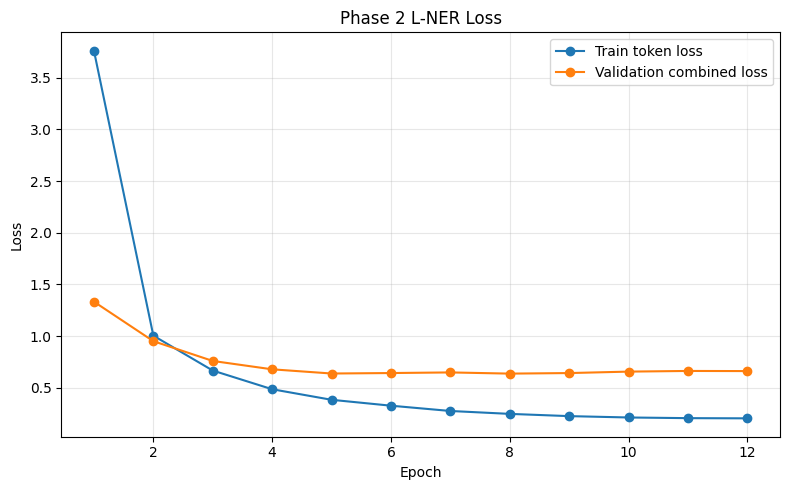

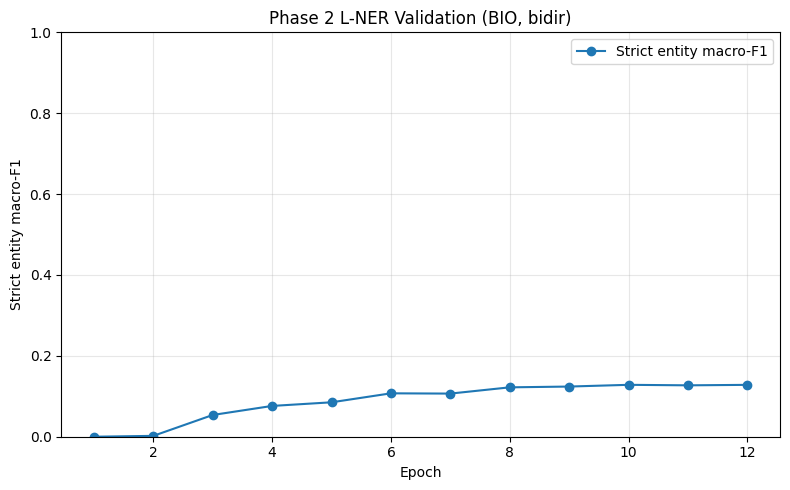

Reloaded best checkpoint at strict macro-F1=0.1283


Predicting Fold 2 (Validation):   0%|          | 0/35 [00:00<?, ?it/s]

Predicting Fold 3 (Test):   0%|          | 0/35 [00:00<?, ?it/s]

Phase 2 complete.
Best checkpoint: /kaggle/working/phase2_lner_decoder_lora_bio_bidir_charbound/best_lner_lora.pt
Fold 2 Prediction JSON (Local Eval): /kaggle/working/phase2_lner_decoder_lora_bio_bidir_charbound/fold2_prediction.json
Fold 3 Prediction JSON: /kaggle/working/phase2_lner_decoder_lora_bio_bidir_charbound/prediction.json
Submission ZIP (Upload to Codabench!): /kaggle/working/phase2_lner_decoder_lora_bio_bidir_charbound/submission.zip


In [6]:
# Phase 2 L-NER experiment: custom byte-level BPE offsets + custom token head + normal floating-point LoRA
# Run this in the SAME notebook after the Phase 1 `model` and `tokenizer` have been loaded.
# Expected existing objects from model2(2).ipynb: `model`, `tokenizer`, and optionally `HF_DATASET_REPO`, `HF_TOKEN`.

import json
import math
import os
import re
import zipfile
from pathlib import Path
from collections import defaultdict

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

# -----------------------------
# Experiment settings
# -----------------------------
LNER_MAX_LEN = 1024             # <= Phase 1 model context length (2048 in model2 notebook)
LNER_WINDOW_STRIDE = 512        # overlap windows to reduce context-edge errors
LNER_BATCH_SIZE = 8
LNER_ACCUMULATION_STEPS = 2
LNER_EPOCHS = 12                 # Early stopping selects the best validation macro-F1 checkpoint.
LNER_PATIENCE = 3                # Stop after this many consecutive epochs without a meaningful F1 gain.
LNER_MIN_DELTA = 1e-4
LNER_CHAR_LOSS_WEIGHT = 0.8      # Character-level BIO boundary loss complements token-level BIO.
MAX_RELATIVE_CHAR_POSITION = 63
# Separate learning rates: adapter weights, unfrozen final decoder layer/norm, and NER heads.
LORA_LR = 2e-4
UNFROZEN_DECODER_LR = 5e-5
NER_HEAD_LR = 5e-4
# This experiment intentionally uses genuine BIO only, throughout alignment, loss, decoding and checkpointing.
LNER_TAG_SCHEME = "BIO"
LNER_BIDIRECTIONAL_ATTENTION = True
LORA_RANK = 32
LORA_ALPHA = 64.0
LORA_DROPOUT = 0.05
LNER_SEED = 42
LNER_NUM_WORKERS = 2

random_seed = LNER_SEED
import random
random.seed(random_seed)
torch.manual_seed(random_seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(random_seed)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# -----------------------------
# Phase 2 file resolution
# -----------------------------
def _find_local_file(filename):
    likely_roots = [Path("/kaggle/input"), Path("/kaggle/working"), Path.cwd()]
    seen = set()
    for root in likely_roots:
        if not root.exists() or str(root) in seen:
            continue
        seen.add(str(root))
        direct = root / filename
        if direct.is_file():
            return direct
        # Limit searching to a few known input/working roots; stop at the first exact basename match.
        try:
            for candidate in root.rglob(filename):
                if candidate.is_file():
                    return candidate
        except (PermissionError, OSError):
            pass
    return None


def phase2_path(filename, subfolder):
    local = _find_local_file(filename)
    if local is not None:
        return str(local)
    # Reuse the dataset repository credentials from the Phase 1 notebook when available.
    if "HF_DATASET_REPO" in globals():
        try:
            from huggingface_hub import hf_hub_download
            token = globals().get("HF_TOKEN", None)
            return hf_hub_download(
                repo_id=HF_DATASET_REPO,
                filename=f"Phase_2_LNER/{subfolder}/{filename}",
                repo_type="dataset",
                token=token,
            )
        except Exception as exc:
            raise FileNotFoundError(
                f"Could not locate {filename} locally or download it from the dataset repository. "
                "Set PHASE2_ROOT to the directory containing Phase_2_LNER."
            ) from exc
    raise FileNotFoundError(
        f"Could not locate {filename}. Put Phase_2_LNER under /kaggle/input or /kaggle/working, "
        "or configure HF_DATASET_REPO/HF_TOKEN as in the Phase 1 notebook."
    )


FOLD1_TEXT_PATH = phase2_path("fold1-text.json", "Train")
FOLD1_GOLD_PATH = phase2_path("fold1-gold.json", "Train")
FOLD2_TEXT_PATH = phase2_path("fold2-text.json", "Train")
FOLD2_GOLD_PATH = phase2_path("fold2-gold.json", "Train")
LABELS_PATH = phase2_path("labels.txt", "Train")
FOLD3_TEXT_PATH = phase2_path("fold3-text.json", "Test")
print("Phase 2 files resolved:", FOLD1_TEXT_PATH, FOLD1_GOLD_PATH, FOLD2_TEXT_PATH, FOLD2_GOLD_PATH, LABELS_PATH, FOLD3_TEXT_PATH, sep="\n  ")

# -----------------------------
# Read Phase 2 JSON formats
# -----------------------------
def read_json_or_jsonl(path):
    with open(path, "r", encoding="utf-8") as f:
        raw = f.read()
    try:
        return json.loads(raw)
    except json.JSONDecodeError:
        rows = []
        for line_no, line in enumerate(raw.splitlines(), 1):
            line = line.strip().rstrip(",")
            if not line:
                continue
            try:
                rows.append(json.loads(line))
            except json.JSONDecodeError as exc:
                raise ValueError(f"Invalid JSON in {path}, line {line_no}") from exc
        return rows


def _first_present(record, keys, default=None):
    for key in keys:
        if key in record:
            return record[key]
    return default


def normalise_documents(raw):
    """Return {str(document_id): document_text}; supports the stated ID -> text layout."""
    if isinstance(raw, dict):
        for container_key in ("documents", "data", "docs", "items"):
            if container_key in raw and isinstance(raw[container_key], (dict, list)):
                return normalise_documents(raw[container_key])
        docs = {}
        for key, value in raw.items():
            if isinstance(value, str):
                docs[str(key)] = value
            elif isinstance(value, dict):
                text = _first_present(value, ("text", "document", "content", "document_text"))
                doc_id = _first_present(value, ("id", "doc_id", "document_id", "docid"), key)
                if isinstance(text, str):
                    docs[str(doc_id)] = text
        if not docs:
            raise ValueError("Could not find document text. Expected a document-ID-to-text JSON object or records with id/text fields.")
        return docs
    if isinstance(raw, list):
        docs = {}
        for row in raw:
            if not isinstance(row, dict):
                continue
            doc_id = _first_present(row, ("id", "doc_id", "document_id", "docid", "documentId"))
            text = _first_present(row, ("text", "document", "content", "document_text"))
            if doc_id is not None and isinstance(text, str):
                docs[str(doc_id)] = text
        if not docs:
            raise ValueError("Could not find document ID/text records in the JSON list.")
        return docs
    raise ValueError(f"Unsupported document JSON root type: {type(raw).__name__}")


# def normalise_entity(entity):
#     if not isinstance(entity, dict):
#         return None
#     start = _first_present(entity, ("start", "start_offset", "start_char", "start_character", "begin"))
#     end = _first_present(entity, ("end", "end_offset", "end_char", "end_character", "stop"))
#     label = _first_present(entity, ("label", "entity_label", "entity_type", "type"))
#     text = _first_present(entity, ("text", "entity_text", "surface"), "")
#     if start is None or end is None or label is None:
#         return None
#     start, end = int(start), int(end)
#     if end <= start:
#         return None
#     return {"start": start, "end": end, "label": str(label).strip(), "text": str(text)}

def normalise_entity(entity):
    # Fix: Handle the official Capstone list format [start, end, label, (optional text)]
    if isinstance(entity, (list, tuple)) and len(entity) >= 3:
        start, end, label = int(entity[0]), int(entity[1]), str(entity[2]).strip()
        text = str(entity[3]) if len(entity) > 3 else ""
        if end <= start:
            return None
        return {"start": start, "end": end, "label": label, "text": text}
        
    # Fallback for dictionary formats
    if not isinstance(entity, dict):
        return None
        
    start = _first_present(entity, ("start", "start_offset", "start_char", "start_character", "begin"))
    end = _first_present(entity, ("end", "end_offset", "end_char", "end_character", "stop"))
    label = _first_present(entity, ("label", "entity_label", "entity_type", "type"))
    text = _first_present(entity, ("text", "entity_text", "surface"), "")
    
    if start is None or end is None or label is None:
        return None
        
    start, end = int(start), int(end)
    if end <= start:
        return None
        
    return {"start": start, "end": end, "label": str(label).strip(), "text": str(text)}


def normalise_gold(raw):
    """Return {str(document_id): [normalized entity dicts]} for document-keyed or record-list JSON."""
    if isinstance(raw, dict):
        for container_key in ("annotations", "entities_by_document", "data", "documents", "records"):
            if container_key in raw and isinstance(raw[container_key], (dict, list)):
                return normalise_gold(raw[container_key])
        out = {}
        for doc_id, value in raw.items():
            if isinstance(value, list):
                ents = [normalise_entity(e) for e in value]
            elif isinstance(value, dict):
                embedded = _first_present(value, ("entities", "annotations", "spans"))
                if isinstance(embedded, list):
                    ents = [normalise_entity(e) for e in embedded]
                elif _first_present(value, ("start", "start_offset", "start_char")) is not None:
                    ent = normalise_entity(value)
                    record_id = _first_present(value, ("doc_id", "document_id", "docid", "id"), doc_id)
                    out.setdefault(str(record_id), [])
                    if ent is not None:
                        out[str(record_id)].append(ent)
                    continue
                else:
                    continue
            else:
                continue
            out[str(doc_id)] = [e for e in ents if e is not None]
        if not out:
            raise ValueError("Could not parse gold annotations. Expected a document-ID-to-entity-list mapping.")
        return out
    if isinstance(raw, list):
        out = defaultdict(list)
        for row in raw:
            if not isinstance(row, dict):
                continue
            doc_id = _first_present(row, ("doc_id", "document_id", "docid", "documentId", "id"))
            embedded = _first_present(row, ("entities", "annotations", "spans"))
            if doc_id is not None and isinstance(embedded, list):
                out[str(doc_id)].extend(e for e in (normalise_entity(x) for x in embedded) if e is not None)
                continue
            ent = normalise_entity(row)
            if doc_id is not None and ent is not None:
                out[str(doc_id)].append(ent)
        if not out:
            raise ValueError("Could not parse gold records from JSON list.")
        return dict(out)
    raise ValueError(f"Unsupported gold JSON root type: {type(raw).__name__}")


fold1_docs = normalise_documents(read_json_or_jsonl(FOLD1_TEXT_PATH))
fold1_gold = normalise_gold(read_json_or_jsonl(FOLD1_GOLD_PATH))
fold2_docs = normalise_documents(read_json_or_jsonl(FOLD2_TEXT_PATH))
fold2_gold = normalise_gold(read_json_or_jsonl(FOLD2_GOLD_PATH))
test_docs = normalise_documents(read_json_or_jsonl(FOLD3_TEXT_PATH))
with open(LABELS_PATH, "r", encoding="utf-8") as f:
    ENTITY_LABELS = [line.strip() for line in f if line.strip()]
# Handle a leading UTF-8 BOM and duplicate blank/duplicate label lines defensively.
ENTITY_LABELS = list(dict.fromkeys(label.lstrip("\ufeff").strip() for label in ENTITY_LABELS if label.strip()))
if not ENTITY_LABELS:
    raise ValueError("labels.txt is empty; cannot construct the entity classifier.")

print(f"Fold 1: {len(fold1_docs)} documents; {sum(len(fold1_gold.get(k, [])) for k in fold1_docs)} entities")
print(f"Fold 2: {len(fold2_docs)} documents; {sum(len(fold2_gold.get(k, [])) for k in fold2_docs)} entities")
print(f"Test:   {len(test_docs)} documents")
print("Entity labels:", ENTITY_LABELS)

# -----------------------------
# Custom byte-level BPE encoder with character offsets
# -----------------------------
def encode_with_character_offsets(tokenizer, text, verify_parity=False):
    """Mirror CustomByteLevelBPE.encode() exactly while tracking Unicode character spans.

    The Phase 1 tokenizer is byte-level. Each UTF-8 byte initially maps to the Unicode
    character that generated it; merged byte tokens combine those spans. End offsets are
    exclusive, matching the Phase 2 character-span annotation convention.
    """
    all_ids, all_offsets = [], []
    if not text:
        return all_ids, all_offsets

    for match in re.finditer(r"\S+|\s+", text):
        chunk = match.group(0)
        ids = list(chunk.encode("utf-8"))
        spans = []
        absolute_char = match.start()
        for local_char, ch in enumerate(chunk):
            char_span = (absolute_char + local_char, absolute_char + local_char + 1)
            spans.extend([char_span] * len(ch.encode("utf-8")))

        # Same greedy merge priority as CustomByteLevelBPE.encode(): lowest merge ID first.
        while len(ids) >= 2:
            eligible = []
            for i in range(len(ids) - 1):
                pair = (ids[i], ids[i + 1])
                if pair in tokenizer.merges:
                    eligible.append((tokenizer.merges[pair], i, pair))
            if not eligible:
                break
            merge_id, _, pair = min(eligible, key=lambda x: (x[0], x[1]))

            new_ids, new_spans = [], []
            i = 0
            while i < len(ids):
                if i < len(ids) - 1 and (ids[i], ids[i + 1]) == pair:
                    new_ids.append(merge_id)
                    new_spans.append((spans[i][0], max(spans[i][1], spans[i + 1][1])))
                    i += 2
                else:
                    new_ids.append(ids[i])
                    new_spans.append(spans[i])
                    i += 1
            ids, spans = new_ids, new_spans

        all_ids.extend(ids)
        all_offsets.extend(spans)

    # Optional parity check against the notebook's original tokenizer implementation.
    # Run this on a representative document once; repeating it for every document doubles
    # the tokenizer work and can be costly for a custom BPE implementation.
    if verify_parity:
        original_ids = tokenizer.encode(text)
        if all_ids != original_ids:
            raise RuntimeError(
                "Offset-aware BPE differs from tokenizer.encode() for this text. "
                "Check the custom tokenizer's merge implementation before training."
            )
    return all_ids, all_offsets


# One-time parity check: avoid running the original tokenizer a second time for every document.
_parity_sample = next(iter(fold1_docs.values()), "")
if _parity_sample:
    _parity_ids, _parity_offsets = encode_with_character_offsets(tokenizer, _parity_sample, verify_parity=True)
    assert len(_parity_ids) == len(_parity_offsets)
    print("Offset-aware BPE parity check passed on one fold-1 document.")


# -----------------------------
# Data, label, offset and token-boundary audit
# -----------------------------
def audit_lner_split(documents, gold_by_doc, split_name):
    from collections import Counter
    label_counts = Counter()
    unknown_labels = Counter()
    invalid_offsets = []
    text_mismatches = []
    all_spans = defaultdict(list)
    total_entities = 0

    print(f"\n{'=' * 16} {split_name} AUDIT {'=' * 16}")
    print("Documents:", len(documents), "| gold document IDs:", len(gold_by_doc))
    missing_text_ids = sorted(set(gold_by_doc) - set(documents))
    print("Gold IDs without corresponding text:", len(missing_text_ids))
    if missing_text_ids:
        print("Examples:", missing_text_ids[:10])

    for doc_id, entities in gold_by_doc.items():
        text = documents.get(str(doc_id))
        if text is None:
            continue
        for entity in entities:
            total_entities += 1
            label = str(entity.get("label", "")).strip()
            label_counts[label] += 1
            if label not in ENTITY_LABELS:
                unknown_labels[label] += 1
            try:
                start, end = int(entity["start"]), int(entity["end"])
            except (KeyError, TypeError, ValueError):
                invalid_offsets.append((doc_id, entity))
                continue
            if start < 0 or end <= start or end > len(text):
                invalid_offsets.append((doc_id, start, end, len(text)))
                continue
            all_spans[str(doc_id)].append((start, end, label))
            annotated_text = str(entity.get("text", ""))
            if annotated_text and text[start:end] != annotated_text:
                text_mismatches.append((str(doc_id), start, end, annotated_text[:80], text[start:end][:80]))

    overlap_examples = []
    overlap_pairs = 0
    for doc_id, spans in all_spans.items():
        spans.sort(key=lambda x: (x[0], x[1]))
        for i, left in enumerate(spans):
            for right in spans[i + 1:]:
                if right[0] >= left[1]:
                    break
                overlap_pairs += 1
                if len(overlap_examples) < 10:
                    overlap_examples.append((doc_id, left, right))

    print("Entities:", total_entities)
    print("Entities by label:")
    for label, count in label_counts.most_common():
        print(f"  {label:30s} {count:8d}")
    print("Unknown labels:", dict(unknown_labels))
    print("Invalid offsets:", len(invalid_offsets), "| text-slice mismatches:", len(text_mismatches))
    print("Overlapping entity pairs:", overlap_pairs)
    if text_mismatches:
        print("Text-slice mismatch examples (doc, start, end, annotation text, source slice):")
        for row in text_mismatches[:5]:
            print(" ", row)

    # A flat BIO sequence cannot represent overlapping/nested entities, and invalid
    # labels/offsets must not be silently dropped during preprocessing.
    if missing_text_ids or unknown_labels or invalid_offsets or overlap_pairs:
        raise ValueError(
            f"{split_name} annotations need fixing before training: gold IDs without text={len(missing_text_ids)}, "
            f"unknown labels={sum(unknown_labels.values())}, invalid offsets={len(invalid_offsets)}, "
            f"overlap pairs={overlap_pairs}. See audit output above."
        )

    # Exact entity spans can only be reconstructed from this token head when both character
    # boundaries coincide with token boundaries. Quantify that limitation on a small sample.
    candidates = [doc_id for doc_id in documents if gold_by_doc.get(str(doc_id)) and len(documents[doc_id]) <= 20000]
    candidates.sort(key=lambda did: (len(documents[did]), str(did)))
    # Spread the sample across the candidate list rather than only taking the shortest documents.
    if len(candidates) > 12:
        positions = [round(i * (len(candidates) - 1) / 11) for i in range(12)]
        sample_ids = [candidates[i] for i in positions]
    else:
        sample_ids = candidates
    total_sampled = start_aligned = end_aligned = both_aligned = 0
    for doc_id in sample_ids:
        text = documents[doc_id]
        _, offsets = encode_with_character_offsets(tokenizer, text)
        token_starts = {a for a, b in offsets if b > a}
        token_ends = {b for a, b in offsets if b > a}
        for entity in gold_by_doc.get(str(doc_id), []):
            a, b = int(entity["start"]), int(entity["end"])
            total_sampled += 1
            has_start, has_end = a in token_starts, b in token_ends
            start_aligned += int(has_start)
            end_aligned += int(has_end)
            both_aligned += int(has_start and has_end)
    if total_sampled:
        print(f"Token-boundary sample: {total_sampled} entities")
        print(f"  start aligned: {start_aligned / total_sampled:.1%}")
        print(f"  end aligned:   {end_aligned / total_sampled:.1%}")
        print(f"  both aligned (necessary for exact boundary using this head): {both_aligned / total_sampled:.1%}")
        if both_aligned / total_sampled < 0.80:
            print("WARNING: many gold entity boundaries fall inside BPE tokens. A token-only BIO head cannot predict those exact character boundaries; the character-level boundary head below is intended to reduce this limitation.")
    else:
        print("No annotated short documents available for token-boundary sampling.")


audit_lner_split(fold1_docs, fold1_gold, "FOLD 1 TRAIN")
audit_lner_split(fold2_docs, fold2_gold, "FOLD 2 VALIDATION")


# -----------------------------
# Character spans -> genuine BIO token tags (no alternate tag-scheme paths remain in this notebook).
# -----------------------------
if LNER_TAG_SCHEME != "BIO":
    raise ValueError("This experiment uses genuine BIO tags only.")
TAG_NAMES = ["O"]
for _label in ENTITY_LABELS:
    TAG_NAMES.extend((f"B-{_label}", f"I-{_label}"))
TAG_TO_ID = {tag: idx for idx, tag in enumerate(TAG_NAMES)}
ID_TO_TAG = {idx: tag for tag, idx in TAG_TO_ID.items()}
IGNORE_INDEX = -100


def normalise_entity_spans(entities, text_length):
    """Validate gold spans; never silently drop labels, clip offsets, or remove overlaps."""
    result = []
    for entity in entities:
        start = int(entity["start"])
        end = int(entity["end"])
        label = str(entity["label"]).strip()
        if label not in ENTITY_LABELS:
            raise ValueError(f"Unknown entity label {label!r}; labels.txt contains {ENTITY_LABELS}")
        if start < 0 or end <= start or end > text_length:
            raise ValueError(f"Invalid entity offsets {(start, end)} for text length {text_length}")
        result.append((start, end, label))
    result.sort(key=lambda item: (item[0], item[1]))
    # A flat BIO sequence cannot represent overlapping/nested annotations.
    for left, right in zip(result, result[1:]):
        if right[0] < left[1]:
            raise ValueError(
                f"Overlapping/nested annotations are not supported by the current flat {LNER_TAG_SCHEME} head: "
                f"{left} and {right}. Use a span-based head for this split."
            )
    return result


def align_offsets_to_bio(offsets, entities, text_length):
    """Align token spans to entity spans. Partial boundary-crossing tokens are ignored in loss."""
    entity_spans = normalise_entity_spans(entities, text_length)
    tag_strings = ["O"] * len(offsets)
    ignore = [False] * len(offsets)
    contained_by_entity = [[] for _ in entity_spans]
    entity_cursor = 0

    # Both token offsets and entity spans are ordered. Use a sweep rather than an O(tokens*entities) scan.
    for token_i, (tok_start, tok_end) in enumerate(offsets):
        if tok_end <= tok_start:
            ignore[token_i] = True
            continue
        while entity_cursor < len(entity_spans) and entity_spans[entity_cursor][1] <= tok_start:
            entity_cursor += 1
        overlaps = []
        j = entity_cursor
        while j < len(entity_spans) and entity_spans[j][0] < tok_end:
            ent_start, ent_end, _ = entity_spans[j]
            if max(tok_start, ent_start) < min(tok_end, ent_end):
                overlaps.append(j)
            j += 1
        if len(overlaps) > 1:
            ignore[token_i] = True
        elif overlaps:
            ent_index = overlaps[0]
            ent_start, ent_end, _ = entity_spans[ent_index]
            if tok_start >= ent_start and tok_end <= ent_end:
                contained_by_entity[ent_index].append(token_i)
            else:
                ignore[token_i] = True

    # Only fully contained tokens are trainable for this entity. Audit above reports how often
    # token boundaries prevent exact character-span reconstruction.
    for entity_index, token_indices in enumerate(contained_by_entity):
        if not token_indices:
            continue
        label = entity_spans[entity_index][2]
        # Genuine BIO: B marks the first included token and I marks all following tokens.
        tag_strings[token_indices[0]] = f"B-{label}"
        for token_i in token_indices[1:]:
            tag_strings[token_i] = f"I-{label}"

    return [IGNORE_INDEX if ignore[i] else TAG_TO_ID[tag_strings[i]] for i in range(len(offsets))]


def make_window_starts(n_tokens, max_len=LNER_MAX_LEN, stride=LNER_WINDOW_STRIDE):
    if n_tokens <= 0:
        return []
    if n_tokens <= max_len:
        return [0]
    stride = min(max(1, stride), max_len)
    return list(range(0, n_tokens, stride))


def fix_bio_window_edges(label_ids):
    """Repair orphan I-tags after an entity is clipped by the left edge of a window."""
    result = list(label_ids)
    active_type = None
    for i, tag_id in enumerate(result):
        if tag_id == IGNORE_INDEX:
            active_type = None
            continue
        tag = ID_TO_TAG[int(tag_id)]
        if tag == "O":
            active_type = None
        elif tag.startswith("B-"):
            active_type = tag[2:]
        elif tag.startswith("I-"):
            ent_type = tag[2:]
            if active_type != ent_type:
                result[i] = TAG_TO_ID[f"B-{ent_type}"]
            active_type = ent_type
    return result


def character_bio_labels(entities, char_start, char_end, text_length):
    """BIO labels at every character position, preserving exact exclusive end offsets."""
    tags = ["O"] * max(0, char_end - char_start)
    for ent_start, ent_end, label in normalise_entity_spans(entities, text_length):
        lo, hi = max(char_start, ent_start), min(char_end, ent_end)
        if hi <= lo:
            continue
        for char_pos in range(lo, hi):
            tags[char_pos - char_start] = f"B-{label}" if char_pos == ent_start else f"I-{label}"
    return [TAG_TO_ID[tag] for tag in tags]


def build_training_windows(documents, gold_by_doc, split_name):
    windows = []
    skipped_empty = 0
    for doc_id, text in tqdm(documents.items(), desc=f"Tokenising {split_name}"):
        token_ids, offsets = encode_with_character_offsets(tokenizer, text)
        if not token_ids:
            skipped_empty += 1
            continue
        entities = gold_by_doc.get(str(doc_id), [])
        labels = align_offsets_to_bio(offsets, entities, len(text))
        for start in make_window_starts(len(token_ids)):
            end = min(start + LNER_MAX_LEN, len(token_ids))
            window_ids = token_ids[start:end]
            window_offsets = offsets[start:end]
            char_start = max(0, int(window_offsets[0][0]))
            char_end = min(len(text), int(window_offsets[-1][1]))
            # Store token offsets local to this window's character slice.
            local_offsets = [(max(0, a - char_start), min(char_end, b) - char_start) for a, b in window_offsets]
            window_labels = fix_bio_window_edges(labels[start:end])
            char_labels = character_bio_labels(entities, char_start, char_end, len(text))
            windows.append({
                "doc_id": str(doc_id),
                "input_ids": window_ids,
                "labels": window_labels,
                "char_offsets": local_offsets,
                "char_labels": char_labels,
                "char_length": len(char_labels),
                "char_start": char_start,
                "char_end": char_end,
            })
            if end == len(token_ids):
                break
    print(f"{split_name}: {len(windows)} windows; skipped empty docs: {skipped_empty}")
    return windows

train_windows = build_training_windows(fold1_docs, fold1_gold, "Fold 1 train")
val_windows_for_loss = build_training_windows(fold2_docs, fold2_gold, "Fold 2 validation")
if not train_windows:
    raise RuntimeError("No training windows were produced; verify paths and document JSON schema.")

# -----------------------------
# Custom token classification head + manual masked cross entropy
# -----------------------------
class CustomTokenClassificationHead(nn.Module):
    def __init__(self, hidden_size, num_tags, dropout=0.1):
        super().__init__()
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_size, num_tags)

    def forward(self, hidden_states):
        return self.classifier(self.dropout(hidden_states))

class CustomCharacterBoundaryHead(nn.Module):
    """Character-level BIO classifier over token states plus within-token position embeddings.

    Token hidden states are broadcast over the characters covered by each token. A learned
    within-token offset embedding lets the head distinguish character boundaries inside a BPE
    token, while averaging overlapping token offsets handles byte tokens sharing one character.
    """
    def __init__(self, hidden_size, num_tags, dropout=0.1, max_relative_position=MAX_RELATIVE_CHAR_POSITION):
        super().__init__()
        self.max_relative_position = int(max_relative_position)
        self.relative_position = nn.Embedding(self.max_relative_position + 1, hidden_size)
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_size, num_tags)

    def character_features(self, hidden_states, char_token_indices, char_relative_positions):
        """Gather one contextual token state per character without per-token GPU synchronizations."""
        batch_size, _, hidden_size = hidden_states.shape
        token_indices = char_token_indices.to(device=hidden_states.device)
        relative_positions = char_relative_positions.to(device=hidden_states.device).clamp_max(self.max_relative_position)
        valid = token_indices.ge(0)
        safe_indices = token_indices.clamp_min(0)
        base_features = torch.gather(
            hidden_states.float(), 1,
            safe_indices.unsqueeze(-1).expand(-1, -1, hidden_size)
        )
        relative_features = self.relative_position(relative_positions)
        return (base_features + relative_features) * valid.unsqueeze(-1).to(base_features.dtype)

    def forward(self, hidden_states, char_token_indices, char_relative_positions):
        char_features = self.character_features(hidden_states, char_token_indices, char_relative_positions)
        return self.classifier(self.dropout(char_features))


# def manual_masked_token_cross_entropy(logits, target_ids, ignore_index=IGNORE_INDEX):
#     """Cross entropy written from log-sum-exp; no nn.CrossEntropyLoss call."""
#     flat_logits = logits.reshape(-1, logits.shape[-1]).float()
#     flat_targets = target_ids.reshape(-1)
#     valid = flat_targets.ne(ignore_index)
#     if not bool(valid.any()):
#         return logits.float().sum() * 0.0
#     selected_logits = flat_logits[valid]
#     selected_targets = flat_targets[valid]
#     log_partition = torch.logsumexp(selected_logits, dim=-1)
#     target_scores = selected_logits.gather(1, selected_targets.unsqueeze(1)).squeeze(1)
#     return (log_partition - target_scores).mean()

def manual_masked_token_cross_entropy(logits, target_ids, ignore_index=IGNORE_INDEX, class_weights=None):
    """Weighted cross entropy implemented from log-sum-exp; supports ignored padding/boundaries."""
    flat_logits = logits.reshape(-1, logits.shape[-1]).float()
    flat_targets = target_ids.reshape(-1)
    valid = flat_targets.ne(ignore_index)
    if not bool(valid.any()):
        return logits.float().sum() * 0.0
    selected_logits = flat_logits[valid]
    selected_targets = flat_targets[valid]
    log_partition = torch.logsumexp(selected_logits, dim=-1)
    target_scores = selected_logits.gather(1, selected_targets.unsqueeze(1)).squeeze(1)
    per_item = log_partition - target_scores
    if class_weights is None:
        weights = torch.ones(logits.shape[-1], device=selected_logits.device, dtype=torch.float32)
        weights[0] = 0.20
    else:
        weights = class_weights.to(device=selected_logits.device, dtype=torch.float32)
    sample_weights = weights[selected_targets]
    return (per_item * sample_weights).sum() / sample_weights.sum().clamp_min(1.0)


def compute_class_weights(windows, key, num_classes, outside_weight=0.20, max_rare_weight=4.0):
    """Moderate inverse-square-root weighting; downweights O and caps rare-class boosts."""
    counts = torch.zeros(num_classes, dtype=torch.float64)
    for row in windows:
        vals = torch.as_tensor(row[key], dtype=torch.long)
        vals = vals[vals != IGNORE_INDEX]
        if vals.numel():
            counts += torch.bincount(vals, minlength=num_classes).to(torch.float64)
    weights = torch.ones(num_classes, dtype=torch.float32)
    positive = counts[1:][counts[1:] > 0]
    reference = float(positive.median()) if positive.numel() else 1.0
    for class_id in range(1, num_classes):
        count = float(counts[class_id])
        weights[class_id] = min(max_rare_weight, max(0.5, (reference / max(1.0, count)) ** 0.5))
    entity_mean = float(weights[1:].mean()) if num_classes > 1 else 1.0
    if entity_mean > 0:
        weights[1:] = (weights[1:] / entity_mean).clamp(max=max_rare_weight)
    weights[0] = outside_weight
    return weights.to(DEVICE), counts.tolist()

# -----------------------------
# Custom unquantized frozen linear + LoRA adapter (normal LoRA)
# -----------------------------
class CustomLoRALinear(nn.Module):
    """Frozen floating-point base Linear with a trainable low-rank LoRA update.

    The base weights are copied to a persistent FP32 buffer. Unlike the INT8 variant,
    this does not quantize weights; it can use substantially more GPU memory.
    """
    def __init__(self, base_linear, rank=LORA_RANK, alpha=LORA_ALPHA, dropout=LORA_DROPOUT):
        super().__init__()
        weight = base_linear.weight.detach().float().clone()
        self.register_buffer("base_weight", weight)
        bias_copy = None if base_linear.bias is None else base_linear.bias.detach().float().clone()
        self.register_buffer("base_bias", bias_copy)
        self.in_features = base_linear.in_features
        self.out_features = base_linear.out_features
        self.rank = int(rank)
        self.scaling = float(alpha) / float(rank)
        self.dropout = nn.Dropout(dropout)
        self.A = nn.Parameter(torch.empty(rank, self.in_features, device=weight.device, dtype=torch.float32))
        self.B = nn.Parameter(torch.zeros(self.out_features, rank, device=weight.device, dtype=torch.float32))
        nn.init.kaiming_uniform_(self.A, a=math.sqrt(5))

    def forward(self, x):
        base = F.linear(x, self.base_weight, self.base_bias)
        delta = F.linear(F.linear(self.dropout(x), self.A), self.B)
        return base + self.scaling * delta


def inject_lora_into_layers(decoder, rank=LORA_RANK, alpha=LORA_ALPHA, dropout=LORA_DROPOUT):
    """Replace Linear modules inside decoder blocks with frozen-weight LoRA wrappers."""
    replaced = []
    def visit(parent, prefix=""):
        for child_name, child in list(parent.named_children()):
            full_name = f"{prefix}.{child_name}" if prefix else child_name
            if isinstance(child, nn.Linear):
                setattr(parent, child_name, CustomLoRALinear(child, rank=rank, alpha=alpha, dropout=dropout))
                replaced.append(full_name)
            else:
                visit(child, full_name)
    for layer_index, layer in enumerate(decoder.layers):
        # CRITICAL: Skip the final layer so it remains 100% trainable
        if layer_index == len(decoder.layers) - 1:
            continue
        visit(layer, f"layers.{layer_index}")
    if not replaced:
        raise RuntimeError("No nn.Linear layers were replaced by LoRA wrappers.")
    return replaced


# -----------------------------
# Prepare existing Phase 1 decoder
# -----------------------------
if "model" not in globals() or "tokenizer" not in globals():
    raise RuntimeError("Run the Phase 1 notebook first so `model` and `tokenizer` exist.")
phase1_decoder = model.module if isinstance(model, nn.DataParallel) else model
phase1_decoder.to(DEVICE)
phase1_decoder.eval()
model_vocab_size = int(phase1_decoder.tok_embeddings.num_embeddings)
max_token_id = max(tokenizer.vocab.keys()) if hasattr(tokenizer, "vocab") and tokenizer.vocab else -1
if max_token_id >= model_vocab_size:
    raise ValueError(
        f"Tokenizer contains token ID {max_token_id}, but Phase 1 embedding table only has "
        f"{model_vocab_size} rows. The tokenizer/model checkpoints do not match."
    )
print(f"Tokenizer/model vocabulary check passed: max token ID {max_token_id}; embedding rows {model_vocab_size}.")
for parameter in phase1_decoder.parameters():
    parameter.requires_grad_(False)

replaced_linear_names = inject_lora_into_layers(phase1_decoder)
# Unfreeze the final transformer layer and the final layernorm
for param in phase1_decoder.layers[-1].parameters():
    param.requires_grad_(True)
for param in phase1_decoder.norm.parameters():
    param.requires_grad_(True)
    
print(f"Inserted normal LoRA wrappers into {len(replaced_linear_names)} linear layers.")
print("Example replaced layers:", replaced_linear_names[:12])

hidden_size = phase1_decoder.tok_embeddings.embedding_dim
ner_head = CustomTokenClassificationHead(hidden_size, len(TAG_NAMES), dropout=0.1).to(DEVICE)
char_head = CustomCharacterBoundaryHead(hidden_size, len(TAG_NAMES), dropout=0.1).to(DEVICE)
TOKEN_CLASS_WEIGHTS, token_tag_counts = compute_class_weights(train_windows, "labels", len(TAG_NAMES))
CHAR_CLASS_WEIGHTS, character_tag_counts = compute_class_weights(train_windows, "char_labels", len(TAG_NAMES))
print("BIO token-tag counts:", {ID_TO_TAG[i]: int(n) for i, n in enumerate(token_tag_counts)})
print("BIO character-tag counts:", {ID_TO_TAG[i]: int(n) for i, n in enumerate(character_tag_counts)})
print("Rare-label class balancing enabled (inverse-square-root, capped); O tag weight = 0.20.")

def lner_attention_forward(self, q, k, v, is_causal=True, attention_mask=None):
    B, H, L_q, D = q.shape
    _, _, L_k, _ = k.shape
    scores = torch.matmul(q, k.transpose(-2, -1).contiguous()) * self.scale

    # For NER, bidirectional context is a useful experiment. Set the flag False to restore
    # the causal mask used in Phase 1. Padded keys remain masked in either mode.
    if is_causal and not LNER_BIDIRECTIONAL_ATTENTION:
        q_positions = torch.arange(L_q, device=q.device).view(L_q, 1)
        k_positions = torch.arange(L_k, device=q.device).view(1, L_k)
        causal_mask = k_positions > q_positions
        scores = scores.masked_fill(causal_mask.view(1, 1, L_q, L_k), float("-inf"))

    if attention_mask is not None:
        pad_mask = attention_mask.view(attention_mask.size(0), 1, 1, attention_mask.size(1))
        scores = scores.masked_fill(pad_mask == 0, float("-inf"))

    weights = torch.softmax(scores, dim=-1)
    return torch.matmul(weights, v.contiguous())

ManualTransformerAttention.forward = lner_attention_forward
print("NER attention:", "bidirectional" if LNER_BIDIRECTIONAL_ATTENTION else "causal")

# This helper mirrors CustomLegalModel.forward but returns final normalized hidden states,
# avoiding the vocabulary-sized output projection during NER.
def decoder_hidden_states(decoder, input_ids, attention_mask=None):
    batch_size, seq_len = input_ids.shape
    if seq_len > decoder.freqs_cis.shape[0]:
        raise ValueError(f"Sequence length {seq_len} exceeds model context {decoder.freqs_cis.shape[0]}")
    freqs_cis = decoder.freqs_cis[:seq_len].to(input_ids.device)
    freqs_cis = torch.view_as_complex(freqs_cis)
    hidden = decoder.tok_embeddings(input_ids)
    for layer in decoder.layers:
        hidden, _ = layer(hidden, freqs_cis, kv_cache=None, attention_mask=attention_mask)
    return decoder.norm(hidden)


# -----------------------------
# Batching
# -----------------------------
PAD_ID = int(getattr(tokenizer, "pad_id", 0))

class LNERWindowDataset(Dataset):
    def __init__(self, windows):
        self.windows = windows
    def __len__(self):
        return len(self.windows)
    def __getitem__(self, index):
        return self.windows[index]


def collate_lner(batch):
    max_len = max(len(row["input_ids"]) for row in batch)
    batch_size = len(batch)
    max_chars = max(int(row.get("char_length", max((int(x[1]) for x in row.get("char_offsets", [])), default=0))) for row in batch)
    input_ids = torch.full((batch_size, max_len), PAD_ID, dtype=torch.long)
    attention_mask = torch.zeros((batch_size, max_len), dtype=torch.long)
    labels = torch.full((batch_size, max_len), IGNORE_INDEX, dtype=torch.long)
    char_token_indices = torch.full((batch_size, max_chars), -1, dtype=torch.long)
    char_relative_positions = torch.zeros((batch_size, max_chars), dtype=torch.long)
    char_labels = torch.full((batch_size, max_chars), IGNORE_INDEX, dtype=torch.long)
    char_lengths = torch.zeros(batch_size, dtype=torch.long)
    for i, row in enumerate(batch):
        length = len(row["input_ids"])
        input_ids[i, :length] = torch.tensor(row["input_ids"], dtype=torch.long)
        attention_mask[i, :length] = 1
        if "labels" in row:
            labels[i, :length] = torch.tensor(row["labels"], dtype=torch.long)
        local_offsets = row.get("char_offsets", [])
        char_length = int(row.get("char_length", max((int(x[1]) for x in local_offsets), default=0)))
        char_lengths[i] = char_length
        # Every character is mapped to a token state and a position within that token.
        # For rare overlapping byte offsets (e.g., non-ASCII characters), keep the first state.
        for token_i, (start, end) in enumerate(local_offsets):
            start, end = max(0, int(start)), min(char_length, int(end))
            if end <= start:
                continue
            for char_i in range(start, end):
                if char_token_indices[i, char_i] < 0:
                    char_token_indices[i, char_i] = token_i
                    char_relative_positions[i, char_i] = min(char_i - start, MAX_RELATIVE_CHAR_POSITION)
        if "char_labels" in row:
            char_labels[i, :char_length] = torch.tensor(row["char_labels"], dtype=torch.long)
    return input_ids, attention_mask, labels, char_token_indices, char_relative_positions, char_labels, char_lengths

train_loader = DataLoader(
    LNERWindowDataset(train_windows), batch_size=LNER_BATCH_SIZE, shuffle=True,
    num_workers=LNER_NUM_WORKERS, collate_fn=collate_lner, pin_memory=(DEVICE.type == "cuda")
)
val_loss_loader = DataLoader(
    LNERWindowDataset(val_windows_for_loss), batch_size=LNER_BATCH_SIZE, shuffle=False,
    num_workers=LNER_NUM_WORKERS, collate_fn=collate_lner, pin_memory=(DEVICE.type == "cuda")
)

# -----------------------------
# Prediction utilities: windows -> averaged token logits -> exact character spans
# -----------------------------
@torch.no_grad()
def predict_document_logits(text, decoder, head, char_head, batch_window_size=4):
    """Return averaged character-level BIO logits for exact character-span decoding."""
    token_ids, offsets = encode_with_character_offsets(tokenizer, text)
    if not token_ids:
        return token_ids, offsets, torch.empty((0, len(TAG_NAMES)), dtype=torch.float32)
    starts = make_window_starts(len(token_ids))
    accum = torch.zeros((len(text), len(TAG_NAMES)), device=DEVICE, dtype=torch.float32)
    counts = torch.zeros((len(text), 1), device=DEVICE, dtype=torch.float32)
    decoder.eval(); head.eval(); char_head.eval()
    use_amp = DEVICE.type == "cuda"
    for block in range(0, len(starts), batch_window_size):
        group_starts = starts[block:block + batch_window_size]
        rows = []
        positions = []
        for start in group_starts:
            end = min(start + LNER_MAX_LEN, len(token_ids))
            window_offsets = offsets[start:end]
            char_start = max(0, int(window_offsets[0][0]))
            char_end = min(len(text), int(window_offsets[-1][1]))
            rows.append({
                "input_ids": token_ids[start:end],
                "char_offsets": [(max(0, a - char_start), min(char_end, b) - char_start) for a, b in window_offsets],
                "char_length": max(0, char_end - char_start),
            })
            positions.append((char_start, char_end))
        input_ids, attention_mask, _, char_token_indices, char_relative_positions, _, char_lengths = collate_lner(rows)
        input_ids = input_ids.to(DEVICE, non_blocking=True)
        attention_mask = attention_mask.to(DEVICE, non_blocking=True)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=use_amp):
            hidden = decoder_hidden_states(decoder, input_ids, attention_mask)
            char_logits = char_head(hidden, char_token_indices, char_relative_positions).float()
        for row_i, (char_start, char_end) in enumerate(positions):
            length = min(char_end - char_start, int(char_lengths[row_i].item()))
            if length <= 0:
                continue
            accum[char_start:char_start + length] += char_logits[row_i, :length]
            counts[char_start:char_start + length] += 1.0
    averaged = accum / counts.clamp_min(1.0)
    return token_ids, offsets, averaged.cpu()

def bio_tags_to_character_spans(tag_ids, offsets):
    """Decode BIO tags into exact spans. Orphan I-tags are repaired as entity starts."""
    spans = []
    active_start = active_end = active_label = None

    def close_active():
        nonlocal active_start, active_end, active_label
        if active_label is not None and active_start is not None and active_end is not None and active_end > active_start:
            spans.append((int(active_start), int(active_end), str(active_label)))
        active_start = active_end = active_label = None

    for tag_id, (start, end) in zip(tag_ids, offsets):
        if tag_id == IGNORE_INDEX or end <= start:
            close_active()
            continue
        tag = ID_TO_TAG[int(tag_id)]
        if tag == "O":
            close_active()
            continue
        prefix, label = tag.split("-", 1)
        if prefix == "B":
            close_active()
            active_start, active_end, active_label = start, end, label
        elif prefix == "I":
            if active_label == label and active_end is not None and start <= active_end:
                active_end = max(active_end, end)
            else:
                close_active()
                active_start, active_end, active_label = start, end, label
    close_active()
    return sorted(set(spans), key=lambda item: (item[0], item[1], item[2]))

def clean_predicted_spans(spans, text):
    cleaned = []
    for start, end, label in spans:
        span_text = text[start:end]
        l_strip = len(span_text) - len(span_text.lstrip(" .,\n\t\r-"))
        r_strip = len(span_text) - len(span_text.rstrip(" .,\n\t\r-"))
        new_start = start + l_strip
        new_end = end - r_strip
        if new_end > new_start:
            cleaned.append((new_start, new_end, label))
    return cleaned

@torch.no_grad()
def predict_document_spans(text, decoder, head, char_head):
    ids, offsets, char_logits = predict_document_logits(text, decoder, head, char_head)
    if not ids:
        return []
    char_offsets = [(i, i + 1) for i in range(len(text))]
    tag_ids = char_logits.argmax(dim=-1).tolist()
    spans = bio_tags_to_character_spans(tag_ids, char_offsets)
    return clean_predicted_spans(spans, text)
    

# def strict_entity_metrics(gold_documents, pred_documents, label_names):
#     gold = set()
#     pred = set()
#     for doc_id, entities in gold_documents.items():
#         for ent in entities:
#             gold.add((str(doc_id), int(ent["start"]), int(ent["end"]), str(ent["label"])))
#     for doc_id, spans in pred_documents.items():
#         for start, end, label in spans:
#             pred.add((str(doc_id), int(start), int(end), str(label)))
#     tp = len(gold & pred)
#     fp = len(pred - gold)
#     fn = len(gold - pred)
#     precision = tp / (tp + fp) if tp + fp else 0.0
#     recall = tp / (tp + fn) if tp + fn else 0.0
#     micro_f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
#     per_label = {}
#     for label in label_names:
#         g = {x for x in gold if x[3] == label}
#         p = {x for x in pred if x[3] == label}
#         ltp, lfp, lfn = len(g & p), len(p - g), len(g - p)
#         lp = ltp / (ltp + lfp) if ltp + lfp else 0.0
#         lr = ltp / (ltp + lfn) if ltp + lfn else 0.0
#         lf = 2 * lp * lr / (lp + lr) if lp + lr else 0.0
#         per_label[label] = {"precision": lp, "recall": lr, "f1": lf, "tp": ltp, "fp": lfp, "fn": lfn}
#     return {"precision": precision, "recall": recall, "micro_f1": micro_f1, "tp": tp, "fp": fp, "fn": fn, "per_label": per_label}

def strict_entity_metrics(gold_documents, pred_documents, label_names):
    gold = set()
    pred = set()
    for doc_id, entities in gold_documents.items():
        for ent in entities:
            gold.add((str(doc_id), int(ent["start"]), int(ent["end"]), str(ent["label"])))
    for doc_id, spans in pred_documents.items():
        for start, end, label in spans:
            pred.add((str(doc_id), int(start), int(end), str(label)))
            
    tp = len(gold & pred)
    fp = len(pred - gold)
    fn = len(gold - pred)
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    micro_f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    
    per_label = {}
    f1_sum = 0.0
    for label in label_names:
        g = {x for x in gold if x[3] == label}
        p = {x for x in pred if x[3] == label}
        ltp, lfp, lfn = len(g & p), len(p - g), len(g - p)
        lp = ltp / (ltp + lfp) if ltp + lfp else 0.0
        lr = ltp / (ltp + lfn) if ltp + lfn else 0.0
        lf = 2 * lp * lr / (lp + lr) if lp + lr else 0.0
        per_label[label] = {"precision": lp, "recall": lr, "f1": lf, "tp": ltp, "fp": lfp, "fn": lfn}
        f1_sum += lf
        
    macro_f1 = f1_sum / max(1, len(label_names))
    
    return {
        "precision": precision, 
        "recall": recall, 
        "micro_f1": micro_f1, 
        "macro_f1": macro_f1,  # Added official metric
        "tp": tp, "fp": fp, "fn": fn, 
        "per_label": per_label
    }

@torch.no_grad()
def evaluate_fold(documents, gold_by_doc, decoder, head, char_head, split_name="validation"):
    decoder.eval(); head.eval(); char_head.eval()
    predictions = {}
    for doc_id, text in tqdm(documents.items(), desc=f"Predicting {split_name}"):
        predictions[str(doc_id)] = predict_document_spans(text, decoder, head, char_head)
    metrics = strict_entity_metrics(gold_by_doc, predictions, ENTITY_LABELS)
    return metrics, predictions


# -----------------------------
# Fine-tune LoRA + token head
# -----------------------------
from torch.optim.lr_scheduler import OneCycleLR

# Keep the learning rate appropriate for each parameter group. `CustomLoRALinear` stores
# frozen base weights as buffers, so only its A/B matrices are trainable adapter parameters.
lora_parameters = [
    p
    for module in phase1_decoder.modules()
    if isinstance(module, CustomLoRALinear)
    for p in (module.A, module.B)
]
lora_parameter_ids = {id(p) for p in lora_parameters}
unfrozen_decoder_parameters = [
    p for p in phase1_decoder.parameters()
    if p.requires_grad and id(p) not in lora_parameter_ids
]
head_parameters = [p for p in ner_head.parameters() if p.requires_grad] + [p for p in char_head.parameters() if p.requires_grad]
trainable_parameters = lora_parameters + unfrozen_decoder_parameters + head_parameters
if not lora_parameters or not head_parameters:
    raise RuntimeError("Expected trainable LoRA adapter parameters and NER-head parameters; check model wrapping.")
trainable_count = sum(p.numel() for p in trainable_parameters)
all_decoder_count = sum(p.numel() for p in phase1_decoder.parameters())
print(f"Trainable parameters: {trainable_count:,}")
print(f"  LoRA adapters: {sum(p.numel() for p in lora_parameters):,} @ max LR {LORA_LR:g}")
print(f"  Unfrozen decoder layer/norm: {sum(p.numel() for p in unfrozen_decoder_parameters):,} @ max LR {UNFROZEN_DECODER_LR:g}")
print(f"  Token + character NER heads: {sum(p.numel() for p in head_parameters):,} @ max LR {NER_HEAD_LR:g}")

optimizer = torch.optim.AdamW(
    [
        {"params": lora_parameters, "lr": LORA_LR},
        {"params": unfrozen_decoder_parameters, "lr": UNFROZEN_DECODER_LR},
        {"params": head_parameters, "lr": NER_HEAD_LR},
    ],
    weight_decay=0.01,
)
USE_AMP = DEVICE.type == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

# Scheduler steps exactly once per optimizer update (not once per micro-batch).
total_steps = ((len(train_loader) + LNER_ACCUMULATION_STEPS - 1) // LNER_ACCUMULATION_STEPS) * LNER_EPOCHS
scheduler = OneCycleLR(
    optimizer,
    max_lr=[LORA_LR, UNFROZEN_DECODER_LR, NER_HEAD_LR],
    total_steps=total_steps,
    pct_start=0.1,
    anneal_strategy="cos",
)

def validate_combined_loss():
    phase1_decoder.eval(); ner_head.eval(); char_head.eval()
    losses = []
    with torch.no_grad():
        for input_ids, attention_mask, labels, char_token_indices, char_relative_positions, char_labels, char_lengths in val_loss_loader:
            input_ids = input_ids.to(DEVICE, non_blocking=True)
            attention_mask = attention_mask.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)
            char_labels = char_labels.to(DEVICE, non_blocking=True)
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
                hidden = decoder_hidden_states(phase1_decoder, input_ids, attention_mask)
                token_logits = ner_head(hidden)
                char_logits = char_head(hidden, char_token_indices, char_relative_positions)
                token_loss = manual_masked_token_cross_entropy(token_logits, labels, class_weights=TOKEN_CLASS_WEIGHTS)
                char_loss = manual_masked_token_cross_entropy(char_logits, char_labels, class_weights=CHAR_CLASS_WEIGHTS)
                loss = token_loss + LNER_CHAR_LOSS_WEIGHT * char_loss
            if torch.isfinite(loss):
                losses.append(float(loss.detach().cpu()))
    return sum(losses) / max(1, len(losses))

history = []
best_f1 = -1.0
stale_epochs = 0
_attention_name = "bidir" if LNER_BIDIRECTIONAL_ATTENTION else "causal"
PHASE2_OUT_DIR = Path(f"/kaggle/working/phase2_lner_decoder_lora_{LNER_TAG_SCHEME.lower()}_{_attention_name}_charbound")
PHASE2_OUT_DIR.mkdir(parents=True, exist_ok=True)
BEST_CHECKPOINT_PATH = PHASE2_OUT_DIR / "best_lner_lora.pt"
# Never accidentally reuse a stale best checkpoint from an earlier failed run.
if BEST_CHECKPOINT_PATH.exists():
    BEST_CHECKPOINT_PATH.unlink()

for epoch in range(1, LNER_EPOCHS + 1):
    phase1_decoder.train(); ner_head.train(); char_head.train()
    batch_losses = []
    running_loss = 0.0
    
    pbar = tqdm(train_loader, desc=f"L-NER epoch {epoch}/{LNER_EPOCHS}")
    
    # Zero gradients BEFORE the epoch begins
    optimizer.zero_grad(set_to_none=True)
    
    for i, (input_ids, attention_mask, labels, char_token_indices, char_relative_positions, char_labels, char_lengths) in enumerate(pbar):
        input_ids = input_ids.to(DEVICE, non_blocking=True)
        attention_mask = attention_mask.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)
        char_labels = char_labels.to(DEVICE, non_blocking=True)
        
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            hidden = decoder_hidden_states(phase1_decoder, input_ids, attention_mask)
            token_logits = ner_head(hidden)
            char_logits = char_head(hidden, char_token_indices, char_relative_positions)
            token_loss = manual_masked_token_cross_entropy(token_logits, labels, class_weights=TOKEN_CLASS_WEIGHTS)
            char_loss = manual_masked_token_cross_entropy(char_logits, char_labels, class_weights=CHAR_CLASS_WEIGHTS)
            loss = (token_loss + LNER_CHAR_LOSS_WEIGHT * char_loss) / LNER_ACCUMULATION_STEPS
            
        if not torch.isfinite(loss):
            raise FloatingPointError(f"Non-finite training loss at epoch {epoch}: {float(loss.detach().cpu())}")
            
        scaler.scale(loss).backward()
        running_loss += loss.item() * LNER_ACCUMULATION_STEPS
        
        is_last_batch = (i + 1) == len(train_loader)
        
        # Step the optimizer rapidly
        if (i + 1) % LNER_ACCUMULATION_STEPS == 0 or is_last_batch:
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(trainable_parameters, max_norm=1.0)
            old_scale = scaler.get_scale()
            scaler.step(optimizer)
            scaler.update()
            # GradScaler can skip optimizer.step() on overflow. Advance OneCycleLR only
            # when the optimizer update actually happened; this removes the warning.
            if scaler.get_scale() >= old_scale:
                scheduler.step()
            
            optimizer.zero_grad(set_to_none=True)
            
            steps_in_cycle = LNER_ACCUMULATION_STEPS if not is_last_batch else ((i + 1) % LNER_ACCUMULATION_STEPS or LNER_ACCUMULATION_STEPS)
            current_train_loss = running_loss / steps_in_cycle
            batch_losses.append(current_train_loss)
            pbar.set_postfix(loss=f"{current_train_loss:.4f}", lr=f"{scheduler.get_last_lr()[0]:.2e}")
            running_loss = 0.0

    train_loss = sum(batch_losses) / max(1, len(batch_losses))
    val_loss = validate_combined_loss()
    val_metrics, _ = evaluate_fold(fold2_docs, fold2_gold, phase1_decoder, ner_head, char_head, split_name=f"fold2 epoch {epoch}")
    
    row = {"epoch": epoch, "train_loss": train_loss, "val_token_loss": val_loss,
           **{k: val_metrics[k] for k in ("precision", "recall", "micro_f1", "macro_f1", "tp", "fp", "fn")},
           "per_label_f1": {label: values["f1"] for label, values in val_metrics["per_label"].items()}}
    history.append(row)
    print(json.dumps(row, indent=2))

    if val_metrics["macro_f1"] > best_f1 + LNER_MIN_DELTA:
        best_f1 = val_metrics["macro_f1"]
        torch.save({
            "decoder_state_dict": phase1_decoder.state_dict(),
            "ner_head_state_dict": ner_head.state_dict(),
            "char_head_state_dict": char_head.state_dict(),
            "entity_labels": ENTITY_LABELS,
            "tag_names": TAG_NAMES,
            "tag_scheme": LNER_TAG_SCHEME,
            "bidirectional_attention": LNER_BIDIRECTIONAL_ATTENTION,
            "lora_rank": LORA_RANK,
            "lora_alpha": LORA_ALPHA,
            "lora_dropout": LORA_DROPOUT,
            "max_len": LNER_MAX_LEN,
            "window_stride": LNER_WINDOW_STRIDE,
            "tokenizer_vocab_size": tokenizer.get_vocab_size(),
            "history": history,
        }, BEST_CHECKPOINT_PATH)
        stale_epochs = 0
        print(f"Saved best checkpoint: {BEST_CHECKPOINT_PATH} (strict macro-F1={best_f1:.4f})")
    else:
        stale_epochs += 1
        print(f"No meaningful macro-F1 improvement for {stale_epochs}/{LNER_PATIENCE} epoch(s).")
        if stale_epochs >= LNER_PATIENCE:
            print(f"Early stopping at epoch {epoch}; best strict macro-F1={best_f1:.4f}.")
            break

# Write experiment history for your report/comparison table.
with open(PHASE2_OUT_DIR / "training_history.json", "w", encoding="utf-8") as f:
    json.dump(history, f, indent=2)

# Plot epoch-level losses and strict entity micro-F1 for experiment tracking.
import matplotlib.pyplot as plt
_epochs = [item["epoch"] for item in history]
plt.figure(figsize=(8, 5))
plt.plot(_epochs, [item["train_loss"] for item in history], marker="o", label="Train token loss")
plt.plot(_epochs, [item["val_token_loss"] for item in history], marker="o", label="Validation combined loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Phase 2 L-NER Loss")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
LOSS_PLOT_PATH = PHASE2_OUT_DIR / "lner_loss_curve.png"
plt.savefig(LOSS_PLOT_PATH, dpi=160)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(_epochs, [item["macro_f1"] for item in history], marker="o", label="Strict entity macro-F1")
plt.xlabel("Epoch")
plt.ylabel("Strict entity macro-F1")
plt.title(f"Phase 2 L-NER Validation ({LNER_TAG_SCHEME}, {_attention_name})")
plt.ylim(0.0, 1.0)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
F1_PLOT_PATH = PHASE2_OUT_DIR / "strict_entity_f1_curve.png"
plt.savefig(F1_PLOT_PATH, dpi=160)
plt.show()

# Reload the best validation checkpoint before inference; assert that it belongs to this run.
if not BEST_CHECKPOINT_PATH.exists():
    raise FileNotFoundError("No best checkpoint was saved. Check the training/validation logs.")
checkpoint = torch.load(BEST_CHECKPOINT_PATH, map_location=DEVICE, weights_only=False)
if checkpoint.get("entity_labels") != ENTITY_LABELS:
    raise ValueError("Checkpoint label list differs from current labels.txt; refusing to load mismatched head.")
if checkpoint.get("tag_names") != TAG_NAMES or checkpoint.get("tag_scheme") != LNER_TAG_SCHEME:
    raise ValueError("Checkpoint tag scheme differs from the current run; refusing to load mismatched NER head.")
if bool(checkpoint.get("bidirectional_attention")) != bool(LNER_BIDIRECTIONAL_ATTENTION):
    raise ValueError("Checkpoint attention mode differs from the current run.")
phase1_decoder.load_state_dict(checkpoint["decoder_state_dict"], strict=True)
ner_head.load_state_dict(checkpoint["ner_head_state_dict"], strict=True)
char_head.load_state_dict(checkpoint["char_head_state_dict"], strict=True)
phase1_decoder.eval(); ner_head.eval(); char_head.eval()
print(f"Reloaded best checkpoint at strict macro-F1={max((row['macro_f1'] for row in checkpoint['history']), default=float('nan')):.4f}")


def clean_predicted_spans(spans, text):
    cleaned = []
    for start, end, label in spans:
        span_text = text[start:end]
        
        # Count how many spaces/punctuation to strip from left and right
        l_strip = len(span_text) - len(span_text.lstrip(" .,\n\t\r-"))
        r_strip = len(span_text) - len(span_text.rstrip(" .,\n\t\r-"))
        
        new_start = start + l_strip
        new_end = end - r_strip
        
        if new_end > new_start:
            cleaned.append((new_start, new_end, label))
    return cleaned
# -----------------------------
# Final fold-3 prediction + Codabench archive
# -----------------------------
# 1. Generate predictions for Fold 2 (Validation) to run Local Evaluator
fold2_predictions = {}
for doc_id, text in tqdm(fold2_docs.items(), desc="Predicting Fold 2 (Validation)"):
    spans = predict_document_spans(text, phase1_decoder, ner_head, char_head)
    # spans = clean_predicted_spans(spans, text)
    fold2_predictions[str(doc_id)] = [[int(start), int(end), label] for start, end, label in spans]

fold2_pred_path = PHASE2_OUT_DIR / "fold2_prediction.json"
with open(fold2_pred_path, "w", encoding="utf-8") as f:
    json.dump(fold2_predictions, f, ensure_ascii=False, indent=2)

# 2. Generate predictions for Fold 3 (Test) for official submission
fold3_predictions = {}
for doc_id, text in tqdm(test_docs.items(), desc="Predicting Fold 3 (Test)"):
    spans = predict_document_spans(text, phase1_decoder, ner_head, char_head)
    # spans = clean_predicted_spans(spans, text)
    # The official schema scores [start_character, end_character, label]
    fold3_predictions[str(doc_id)] = [[int(start), int(end), label] for start, end, label in spans]

prediction_path = PHASE2_OUT_DIR / "prediction.json"
with open(prediction_path, "w", encoding="utf-8") as f:
    json.dump(fold3_predictions, f, ensure_ascii=False, indent=2)

submission_zip_path = PHASE2_OUT_DIR / "submission.zip"
with zipfile.ZipFile(submission_zip_path, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    zf.write(prediction_path, arcname="prediction.json")

# Sanity checks for official test set
assert set(fold3_predictions.keys()) == set(test_docs.keys()), "Some test document IDs are missing or extra."
with zipfile.ZipFile(submission_zip_path, "r") as zf:
    assert zf.namelist() == ["prediction.json"], f"Unexpected zip contents: {zf.namelist()}"

print("Phase 2 complete.")
print("Best checkpoint:", BEST_CHECKPOINT_PATH)
print("Fold 2 Prediction JSON (Local Eval):", fold2_pred_path)
print("Fold 3 Prediction JSON:", prediction_path)
print("Submission ZIP (Upload to Codabench!):", submission_zip_path)

# fold3_predictions = {}
# for doc_id, text in tqdm(test_docs.items(), desc="Predicting fold 3"):
#     spans = predict_document_spans(text, phase1_decoder, ner_head, char_head)
#     # The official schema scores [start_character, end_character, label]; entity text is optional.
#     fold3_predictions[str(doc_id)] = [[int(start), int(end), label] for start, end, label in spans]

# prediction_path = PHASE2_OUT_DIR / "prediction.json"
# with open(prediction_path, "w", encoding="utf-8") as f:
#     json.dump(fold3_predictions, f, ensure_ascii=False, indent=2)

# submission_zip_path = PHASE2_OUT_DIR / "submission.zip"
# with zipfile.ZipFile(submission_zip_path, "w", compression=zipfile.ZIP_DEFLATED) as zf:
#     zf.write(prediction_path, arcname="prediction.json")

# # Sanity checks: every official test ID appears and the zip entry is at its root.
# assert set(fold3_predictions.keys()) == set(test_docs.keys()), "Some test document IDs are missing or extra."
# with zipfile.ZipFile(submission_zip_path, "r") as zf:
#     assert zf.namelist() == ["prediction.json"], f"Unexpected zip contents: {zf.namelist()}"

# print("Phase 2 complete.")
# print("Best checkpoint:", BEST_CHECKPOINT_PATH)
# print("Prediction JSON:", prediction_path)
# print("Submission ZIP:", submission_zip_path)
# print("Loss plot:", LOSS_PLOT_PATH)
# print("Strict-F1 plot:", F1_PLOT_PATH)
# print("Sample prediction:", next(iter(fold3_predictions.items()), None))


In [ ]:
# -----------------------------
# Run the Local Evaluator on Fold 2
# -----------------------------
eval_script_path = _find_local_file("evaluate_phase2.py")

if eval_script_path is None:
    print("Could not find evaluate_phase2.py in /kaggle/input.")
else:
    print(f"Running evaluation using: {eval_script_path}")
    !python {eval_script_path} \
        --truth {FOLD2_GOLD_PATH} \
        --prediction {fold2_pred_path} \
        --labels {LABELS_PATH}